## IMPORT GRAPH

OK: ogni paziente ha un solo Oncotree Code.
Righe merged annotate con Oncotree Code: 21228
Pazienti annotati: 1930

Istologie / Oncotree Code presenti nel dataset:


,n_rows,n_patients,n_genes
Oncotree Code,,,
LUAD,16104,1540,676
NSCLC,1892,157,435
LUSC,2102,144,436
LUNE,374,24,220
NSCLCPD,335,21,211
LNET,122,13,85
LUAS,81,8,60
SARCL,77,7,56
LUCA,15,5,14


Creato gruppo LUAD_NSCLC (LUAD+NSCLC): 1697 pazienti, 17996 righe, 690 geni
Creato gruppo LUSC_NSCLC (LUSC+NSCLC): 301 pazienti, 3994 righe, 512 geni

Riepilogo gruppi analizzati:


,Oncotree_Group,Included_Oncotree_Codes,n_patients,n_rows,n_genes
0,LUAD_NSCLC,LUAD+NSCLC,1697,17996,690
1,LUSC_NSCLC,LUSC+NSCLC,301,3994,512



[LUAD_NSCLC] Pazienti: 1697
[LUAD_NSCLC] Geni: 690
[LUAD_NSCLC] Edges after filters: 2774
[LUAD_NSCLC] KRAS subgraph: 359 genes, 2774 edges


C:\Users\ironl\AppData\Local\Temp\ipykernel_13748\1039527490.py:411: UserWarning: 

The connectionstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(


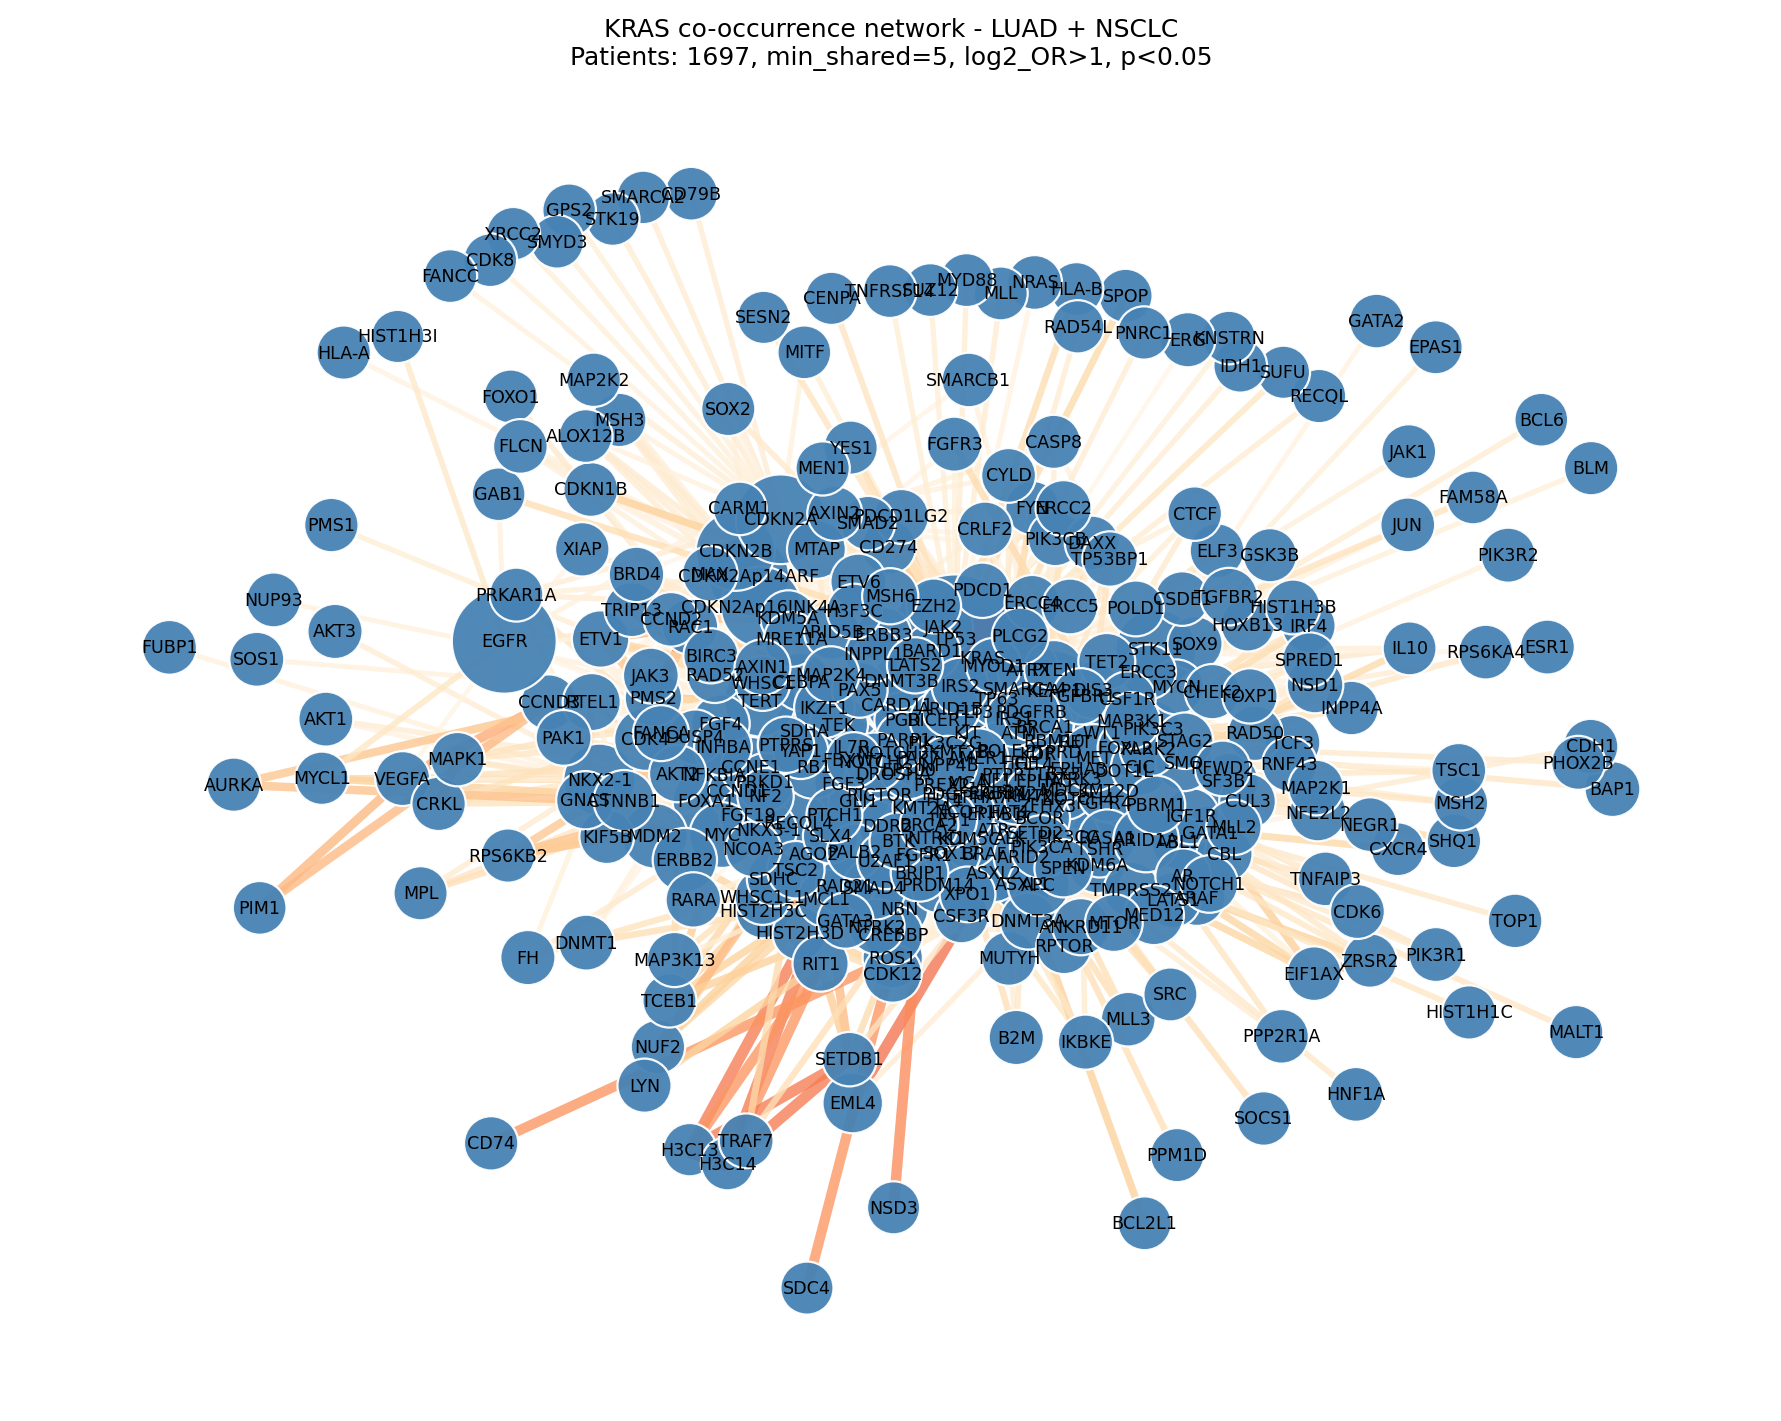

[LUAD_NSCLC] Figura salvata in: data_lung\networks_by_oncotree_groups\kras_network_LUAD_NSCLC.png

[LUSC_NSCLC] Pazienti: 301
[LUSC_NSCLC] Geni: 512
[LUSC_NSCLC] Edges after filters: 288
[LUSC_NSCLC] KRAS subgraph: 111 genes, 287 edges


C:\Users\ironl\AppData\Local\Temp\ipykernel_13748\1039527490.py:411: UserWarning: 

The connectionstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(


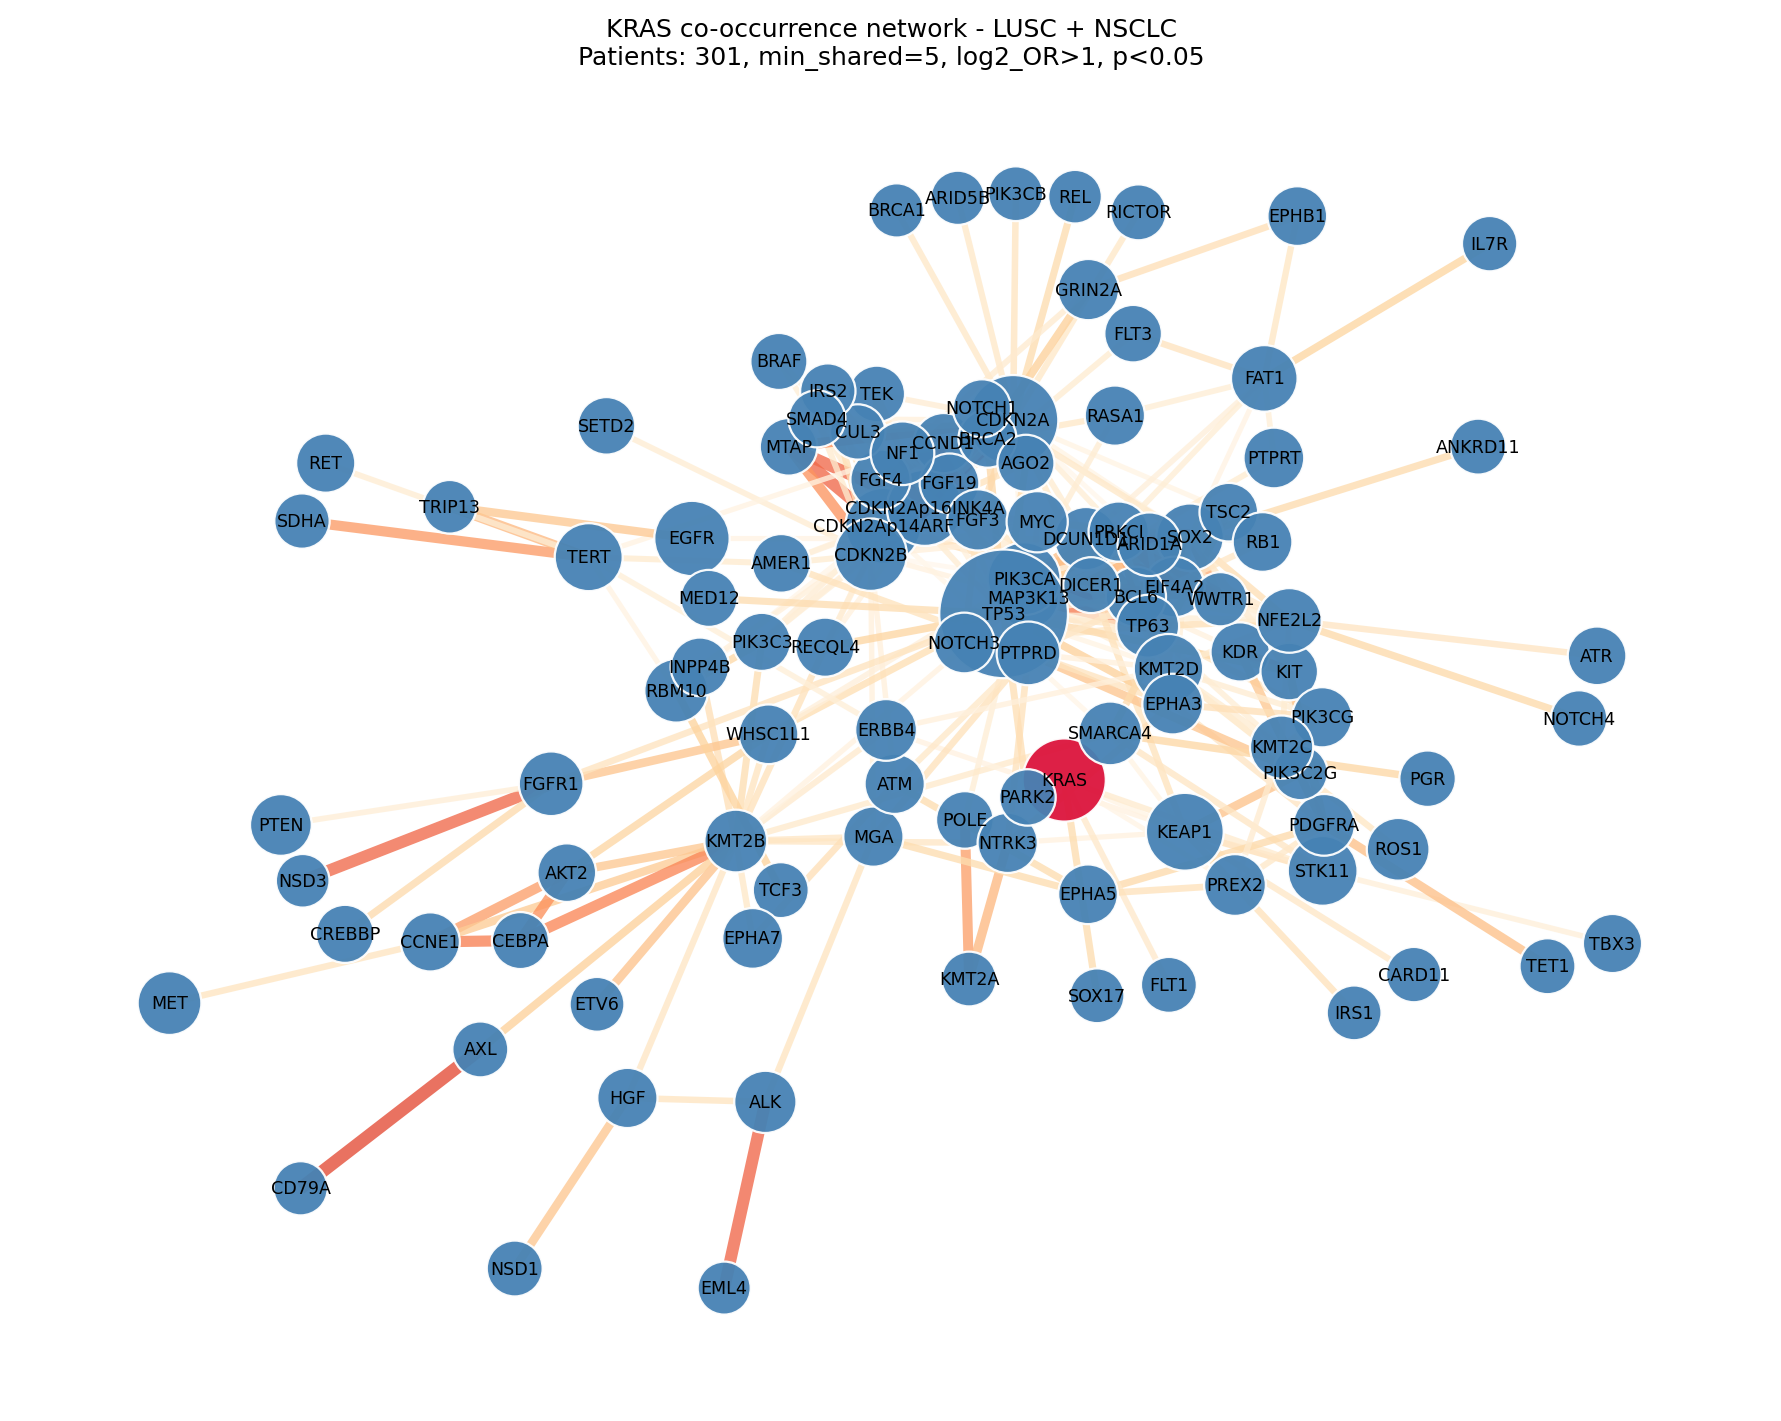

[LUSC_NSCLC] Figura salvata in: data_lung\networks_by_oncotree_groups\kras_network_LUSC_NSCLC.png


In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import fisher_exact

# =========================
# PARAMETRI
# =========================

min_log2_or = 1
max_p_value = 0.05
min_shared = 5
max_hops_from_kras = None

min_patients_for_network = 10

data_dir = Path("data_lung")

file_path_merged = data_dir / "merged_mutations_cna_sv.csv"
file_path_filtered = data_dir / "filtered_data_LUNG.csv"

output_dir = data_dir / "networks_by_oncotree_groups"
output_dir.mkdir(exist_ok=True)

# =========================
# GRUPPI ONCOTREE DA ANALIZZARE
# =========================

oncotree_groups = {
    "LUAD_NSCLC": ["LUAD", "NSCLC"],
    "LUSC_NSCLC": ["LUSC", "NSCLC"],
    # "LUSC":["LUSC"],
    # "LUAD":["LUAD"],
}

# =========================
# CARICAMENTO DATASET
# =========================

df_merge = pd.read_csv(file_path_merged, low_memory=False)
df_filtered = pd.read_csv(file_path_filtered, low_memory=False)

required_merged_cols = {"Patient_ID", "Hugo_Symbol"}
required_filtered_cols = {"Patient_ID", "Oncotree Code"}

missing_merged = required_merged_cols - set(df_merge.columns)
missing_filtered = required_filtered_cols - set(df_filtered.columns)

if missing_merged:
    raise ValueError(f"Colonne mancanti in merged_mutations_cna_sv.csv: {missing_merged}")

if missing_filtered:
    raise ValueError(f"Colonne mancanti in filtered_data_LUNG.csv: {missing_filtered}")

# =========================
# MAPPA PAZIENTE -> ONCOTREE CODE
# =========================

patient_oncotree = (
    df_filtered[["Patient_ID", "Oncotree Code"]]
    .dropna()
    .drop_duplicates()
)

multi_oncotree = (
    patient_oncotree
    .groupby("Patient_ID")["Oncotree Code"]
    .nunique()
)

patients_with_multiple_codes = multi_oncotree[multi_oncotree > 1]

if len(patients_with_multiple_codes) > 0:
    print("ATTENZIONE: alcuni pazienti hanno più Oncotree Code.")
    print(patients_with_multiple_codes.head())
else:
    print("OK: ogni paziente ha un solo Oncotree Code.")

# Dataset merged annotato con Oncotree Code, utile per riepilogo generale
df_merge_oncotree = df_merge.merge(
    patient_oncotree,
    on="Patient_ID",
    how="left"
)

df_merge_oncotree = df_merge_oncotree.dropna(subset=["Oncotree Code"]).copy()

print("Righe merged annotate con Oncotree Code:", len(df_merge_oncotree))
print("Pazienti annotati:", df_merge_oncotree["Patient_ID"].nunique())

# =========================
# RIEPILOGO ONCOTREE PRESENTI
# =========================

oncotree_summary = (
    df_merge_oncotree
    .groupby("Oncotree Code")
    .agg(
        n_rows=("Hugo_Symbol", "size"),
        n_patients=("Patient_ID", "nunique"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nIstologie / Oncotree Code presenti nel dataset:")

try:
    display(oncotree_summary)
except NameError:
    print(oncotree_summary)

oncotree_summary.to_csv(output_dir / "oncotree_summary_original_codes.csv")

# =========================
# CREAZIONE DATAFRAME SOLO PER I DUE GRUPPI
# =========================

dfs_by_group = {}

group_summary_rows = []

for group_name, codes in oncotree_groups.items():

    patients_in_group = (
        patient_oncotree.loc[
            patient_oncotree["Oncotree Code"].isin(codes),
            "Patient_ID"
        ]
        .drop_duplicates()
    )

    df_group = df_merge[
        df_merge["Patient_ID"].isin(patients_in_group)
    ].copy()

    df_group["Oncotree_Group"] = group_name
    df_group["Included_Oncotree_Codes"] = "+".join(codes)

    dfs_by_group[group_name] = df_group

    output_csv = output_dir / f"merged_mutations_cna_sv_{group_name}.csv"
    df_group.to_csv(output_csv, index=False)

    n_patients = df_group["Patient_ID"].nunique()
    n_rows = len(df_group)
    n_genes = df_group["Hugo_Symbol"].nunique()

    group_summary_rows.append({
        "Oncotree_Group": group_name,
        "Included_Oncotree_Codes": "+".join(codes),
        "n_patients": n_patients,
        "n_rows": n_rows,
        "n_genes": n_genes
    })

    print(
        f"Creato gruppo {group_name} ({'+'.join(codes)}): "
        f"{n_patients} pazienti, {n_rows} righe, {n_genes} geni"
    )

group_summary = pd.DataFrame(group_summary_rows)
group_summary.to_csv(output_dir / "oncotree_group_summary.csv", index=False)

print("\nRiepilogo gruppi analizzati:")

try:
    display(group_summary)
except NameError:
    print(group_summary)

# =========================
# FUNZIONE PER COSTRUIRE NETWORK
# =========================

def build_kras_network_for_group(df_code, group_name):
    """
    Costruisce la network di co-occorrenza dei geni per un gruppo Oncotree aggregato.
    Esempi:
    - LUAD_NSCLC = LUAD + NSCLC
    - LUSC_NSCLC = LUSC + NSCLC
    """

    n_patients = df_code["Patient_ID"].nunique()

    if n_patients < min_patients_for_network:
        print(f"\n[{group_name}] Saltato: solo {n_patients} pazienti.")
        return None, None, None

    pairs = (
        df_code[["Patient_ID", "Hugo_Symbol"]]
        .dropna()
        .drop_duplicates()
    )

    if pairs.empty:
        print(f"\n[{group_name}] Nessuna coppia Patient_ID/Hugo_Symbol disponibile.")
        return None, None, None

    patient_gene_m = (
        pd.crosstab(pairs["Patient_ID"], pairs["Hugo_Symbol"])
        .astype(bool)
        .astype(int)
    )

    N_m = patient_gene_m.shape[0]
    gene_counts_m = patient_gene_m.sum(axis=0)

    if patient_gene_m.shape[1] < 2:
        print(f"\n[{group_name}] Meno di 2 geni disponibili, network non costruibile.")
        return None, None, None

    co_m = patient_gene_m.T @ patient_gene_m

    co_np = co_m.to_numpy(copy=True)
    np.fill_diagonal(co_np, 0)

    co_m = pd.DataFrame(
        co_np,
        index=co_m.index,
        columns=co_m.columns
    )

    edges_m = (
        co_m.where(np.triu(np.ones(co_m.shape), k=1).astype(bool))
        .stack()
        .rename("a_both")
        .rename_axis(index=["Gene1", "Gene2"])
        .reset_index()
    )

    edges_m = edges_m.dropna(subset=["a_both"]).copy()
    edges_m["a_both"] = edges_m["a_both"].astype(int)

    rows = []

    for row in edges_m.itertuples(index=False):
        g1, g2, a = row.Gene1, row.Gene2, int(row.a_both)

        b = int(gene_counts_m[g1] - a)
        c = int(gene_counts_m[g2] - a)
        d = int(N_m - a - b - c)

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        log2_or = np.log2(
            ((a + 0.5) * (d + 0.5)) /
            ((b + 0.5) * (c + 0.5))
        )

        rows.append([
            g1,
            g2,
            a,
            b,
            c,
            d,
            odds_ratio,
            log2_or,
            p_value
        ])

    results_m = pd.DataFrame(
        rows,
        columns=[
            "Gene1",
            "Gene2",
            "a_both",
            "b_g1_only",
            "c_g2_only",
            "d_neither",
            "odds_ratio",
            "log2_OR",
            "p_value"
        ]
    )

    edges_plot = results_m[
        (results_m["log2_OR"] > min_log2_or)
        & (results_m["p_value"] < max_p_value)
        & (results_m["a_both"] >= min_shared)
        ].sort_values(
        ["p_value", "log2_OR"],
        ascending=[True, False]
    ).copy()

    print(f"\n[{group_name}] Pazienti: {N_m}")
    print(f"[{group_name}] Geni: {patient_gene_m.shape[1]}")
    print(f"[{group_name}] Edges after filters: {len(edges_plot)}")

    # Salvo risultati statistici completi e filtrati
    results_m.to_csv(
        output_dir / f"cooccurrence_results_{group_name}.csv",
        index=False
    )

    edges_plot.to_csv(
        output_dir / f"cooccurrence_edges_filtered_{group_name}.csv",
        index=False
    )

    G_plot = nx.Graph()

    for _, row in edges_plot.iterrows():
        G_plot.add_edge(
            row["Gene1"],
            row["Gene2"],
            log2_or=float(row["log2_OR"]),
            p_value=float(row["p_value"]),
            shared=int(row["a_both"]),
        )

    if G_plot.number_of_nodes() == 0 or G_plot.number_of_edges() == 0:
        print(f"[{group_name}] No edges to display with current thresholds.")
        return results_m, edges_plot, G_plot

    kras_nodes = [n for n in G_plot.nodes() if str(n).upper() == "KRAS"]

    if not kras_nodes:
        print(f"[{group_name}] KRAS non presente con questi threshold. Prova a rilassare i filtri.")
        return results_m, edges_plot, G_plot

    kras_node = kras_nodes[0]

    distances = nx.single_source_shortest_path_length(G_plot, kras_node)

    if max_hops_from_kras is None:
        keep_nodes = set(distances.keys())
    else:
        keep_nodes = {
            n for n, d in distances.items()
            if d <= max_hops_from_kras
        }

    G_kras = G_plot.subgraph(keep_nodes).copy()

    print(
        f"[{group_name}] KRAS subgraph: "
        f"{G_kras.number_of_nodes()} genes, "
        f"{G_kras.number_of_edges()} edges"
    )

    if G_kras.number_of_edges() == 0:
        return results_m, edges_plot, G_kras

    local_dist = nx.single_source_shortest_path_length(G_kras, kras_node)

    shells = [[kras_node]] + [
        [n for n in G_kras.nodes() if local_dist[n] == d]
        for d in range(1, max(local_dist.values()) + 1)
    ]

    pos0 = nx.shell_layout(G_kras, nlist=shells)
    pos0[kras_node] = np.array([0.0, 0.0])

    pos = nx.spring_layout(
        G_kras,
        seed=42,
        k=0.9,
        pos=pos0,
        fixed=[kras_node],
        center=(0, 0),
        iterations=200
    )

    support = gene_counts_m.to_dict()

    support_vals = [
        float(support.get(n, 1))
        for n in G_kras.nodes()
    ]

    s_min = min(support_vals) if support_vals else 1.0
    s_max = max(support_vals) if support_vals else 1.0

    if s_max == s_min:
        node_sizes = [1000 for _ in G_kras.nodes()]
    else:
        node_sizes = [
            450 + 2200 * (
                    (float(support.get(n, s_min)) - s_min) /
                    (s_max - s_min)
            )
            for n in G_kras.nodes()
        ]

    node_colors = [
        "crimson" if str(n).upper() == "KRAS" else "steelblue"
        for n in G_kras.nodes()
    ]

    edge_vals = [
        G_kras[u][v].get("log2_or", 1.0)
        for u, v in G_kras.edges()
    ]

    max_edge = max(edge_vals) if edge_vals else 1.0

    edge_widths = [
        1.4 + 5.2 * (w / max_edge)
        for w in edge_vals
    ]

    plt.figure(figsize=(10, 8), dpi=180)

    nx.draw_networkx_edges(
        G_kras,
        pos,
        width=edge_widths,
        alpha=0.78,
        edge_color=edge_vals,
        edge_cmap=plt.cm.OrRd,
        edge_vmin=min(edge_vals) if edge_vals else 0.0,
        edge_vmax=max(edge_vals) if edge_vals else 1.0,
        connectionstyle="arc3,rad=0.06",
    )

    nx.draw_networkx_nodes(
        G_kras,
        pos,
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.95,
        linewidths=0.9,
        edgecolors="white",
    )

    nx.draw_networkx_labels(
        G_kras,
        pos,
        labels={n: n for n in G_kras.nodes()},
        font_size=7
    )

    plt.title(
        f"KRAS co-occurrence network - {group_name.replace('_', ' + ')}\n"
        f"Patients: {N_m}, min_shared={min_shared}, "
        f"log2_OR>{min_log2_or}, p<{max_p_value}",
        fontsize=10
    )

    plt.axis("off")
    plt.tight_layout()

    fig_path = output_dir / f"kras_network_{group_name}.png"
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")

    plt.show()

    print(f"[{group_name}] Figura salvata in: {fig_path}")

    return results_m, edges_plot, G_kras


# =========================
# COSTRUZIONE NETWORK SOLO PER I DUE GRUPPI
# =========================

results_by_group = {}
edges_by_group = {}
graphs_by_group = {}

for group_name, df_group in dfs_by_group.items():
    results_m, edges_plot, G_kras = build_kras_network_for_group(
        df_code=df_group,
        group_name=group_name
    )

    results_by_group[group_name] = results_m
    edges_by_group[group_name] = edges_plot
    graphs_by_group[group_name] = G_kras

# =========================
# ALIAS PER MANTENERE COMPATIBILI LE ANALISI SUCCESSIVE
# =========================
# Se nel codice dopo usavi ancora results_by_oncotree, edges_by_oncotree,
# graphs_by_oncotree o dfs_by_oncotree, così non devi cambiare tutto.

dfs_by_oncotree = dfs_by_group
results_by_oncotree = results_by_group
edges_by_oncotree = edges_by_group
graphs_by_oncotree = graphs_by_group

***
## HUB MUTATION centrality metrics

In [2]:
# =========================
# HUB METRICS PER GRUPPI ONCOTREE
# LUAD + NSCLC
# LUSC + NSCLC
# =========================

hub_output_dir = output_dir / "hub_metrics_by_oncotree_groups"
hub_output_dir.mkdir(exist_ok=True)

# Se True, calcola hub metrics solo sui grafi che contengono KRAS.
# Consigliato nel tuo caso, perché stai studiando il KRAS subgraph.
require_kras = True

top_n = 20

hub_tables_by_group = {}

# Mappa descrittiva dei gruppi
group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

def compute_hub_metrics_for_graph(G_hub, graph_name, require_kras=True):
    """
    Calcola le metriche hub per un grafo NetworkX.
    In questo caso graph_name identifica un gruppo Oncotree aggregato:
    - LUAD_NSCLC = LUAD + NSCLC
    - LUSC_NSCLC = LUSC + NSCLC

    Se require_kras=True, salta i grafi che non contengono KRAS.
    """

    if G_hub is None:
        print(f"[{graph_name}] Saltato: grafo None.")
        return None

    if G_hub.number_of_nodes() == 0 or G_hub.number_of_edges() == 0:
        print(f"[{graph_name}] Saltato: grafo vuoto o senza edges.")
        return None

    has_kras = any(str(n).upper() == "KRAS" for n in G_hub.nodes())

    if require_kras and not has_kras:
        print(f"[{graph_name}] Saltato: KRAS non presente nel grafo.")
        return None

    # =========================
    # Decide whether to include eigenvector centrality
    # =========================

    use_eigenvector = True

    if nx.density(G_hub) < 0.1:
        use_eigenvector = False
        print(f"[{graph_name}] Eigenvector centrality NON inclusa: grafo molto sparso.")
    elif not nx.is_connected(G_hub):
        use_eigenvector = False
        print(f"[{graph_name}] Eigenvector centrality NON inclusa: grafo disconnesso.")
    else:
        print(f"[{graph_name}] Eigenvector centrality inclusa.")

    # =========================
    # Basic centrality metrics
    # =========================

    degree = dict(G_hub.degree())

    strength = {
        n: sum(G_hub[n][nbr].get("log2_or", 1.0) for nbr in G_hub.neighbors(n))
        for n in G_hub.nodes()
    }

    betweenness = nx.betweenness_centrality(
        G_hub,
        normalized=True,
        weight=None
    )

    closeness = nx.closeness_centrality(G_hub)

    # =========================
    # Eigenvector centrality
    # =========================

    if use_eigenvector:
        try:
            eigenvector = nx.eigenvector_centrality_numpy(G_hub)
        except Exception as e:
            eigenvector = {n: np.nan for n in G_hub.nodes()}
            use_eigenvector = False
            print(f"[{graph_name}] Eigenvector centrality fallita e NON inclusa.")
            print("Errore:", e)
    else:
        eigenvector = {n: np.nan for n in G_hub.nodes()}

    # =========================
    # Create hub table
    # =========================

    readable_group_name = group_labels.get(graph_name, graph_name)

    hub_table = pd.DataFrame({
        "Oncotree_Group": graph_name,
        "Included_Oncotree_Codes": readable_group_name,
        "Gene": list(G_hub.nodes()),
        "Degree": [degree[n] for n in G_hub.nodes()],
        "Node Strength": [strength[n] for n in G_hub.nodes()],
        "Betweenness": [betweenness[n] for n in G_hub.nodes()],
        "Closeness": [closeness[n] for n in G_hub.nodes()],
        "Eigenvector": [eigenvector[n] for n in G_hub.nodes()],
        "Contains_KRAS": has_kras,
        "Graph_nodes": G_hub.number_of_nodes(),
        "Graph_edges": G_hub.number_of_edges(),
        "Graph_density": nx.density(G_hub),
    })

    # =========================
    # Additional useful metrics
    # =========================

    n_nodes = G_hub.number_of_nodes()
    denom = (n_nodes - 1) if n_nodes > 1 else 1

    hub_table["Degree_norm"] = hub_table["Degree"] / denom

    hub_table["Mean_log2_or_per_edge"] = (
            hub_table["Node Strength"] / hub_table["Degree"].replace(0, pd.NA)
    )

    # =========================
    # Composite HubScore
    # =========================

    if use_eigenvector:
        hub_table["HubScore"] = (
                hub_table["Degree"].rank(pct=True) * 0.20
                + hub_table["Node Strength"].rank(pct=True) * 0.20
                + hub_table["Betweenness"].rank(pct=True) * 0.20
                + hub_table["Closeness"].rank(pct=True) * 0.20
                + hub_table["Eigenvector"].fillna(0).rank(pct=True) * 0.20
        )

        score_description = (
            "HubScore = 20% Degree + 20% Node Strength + 20% Betweenness "
            "+ 20% Closeness + 20% Eigenvector"
        )

    else:
        hub_table["HubScore"] = (
                hub_table["Degree"].rank(pct=True) * 0.25
                + hub_table["Node Strength"].rank(pct=True) * 0.25
                + hub_table["Betweenness"].rank(pct=True) * 0.25
                + hub_table["Closeness"].rank(pct=True) * 0.25
        )

        score_description = (
            "HubScore = 25% Degree + 25% Node Strength + 25% Betweenness "
            "+ 25% Closeness"
        )

    hub_table = hub_table.sort_values("HubScore", ascending=False).reset_index(drop=True)

    # =========================
    # Display results
    # =========================

    print("\n" + "=" * 70)
    print(f"Graph analyzed: {graph_name} ({readable_group_name})")
    print(f"Nodes: {G_hub.number_of_nodes()} | Edges: {G_hub.number_of_edges()}")
    print(f"Density: {nx.density(G_hub):.4f}")
    print(f"Contains KRAS: {has_kras}")
    print(score_description)
    print(f"\nTop {top_n} hub genes:")

    display_cols = [
        "Oncotree_Group",
        "Included_Oncotree_Codes",
        "Gene",
        "Degree",
        "Degree_norm",
        "Node Strength",
        "Mean_log2_or_per_edge",
        "Betweenness",
        "Closeness",
    ]

    if use_eigenvector:
        display_cols.append("Eigenvector")

    display_cols.append("HubScore")

    try:
        display(hub_table[display_cols].head(top_n))
    except NameError:
        print(hub_table[display_cols].head(top_n))

    # Salvataggio CSV per singolo gruppo
    output_file = hub_output_dir / f"hub_metrics_{graph_name}.csv"
    hub_table.to_csv(output_file, index=False)

    print(f"[{graph_name}] Hub metrics salvate in: {output_file}")

    return hub_table


# =========================
# CALCOLO HUB METRICS SOLO PER I DUE GRUPPI
# =========================

# Usa direttamente i grafi creati prima:
# graphs_by_group["LUAD_NSCLC"]
# graphs_by_group["LUSC_NSCLC"]

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

for group_name in target_groups:

    if group_name not in graphs_by_group:
        print(f"[{group_name}] Non trovato in graphs_by_group. Saltato.")
        continue

    G = graphs_by_group[group_name]

    hub_table = compute_hub_metrics_for_graph(
        G_hub=G,
        graph_name=group_name,
        require_kras=require_kras
    )

    if hub_table is not None:
        hub_tables_by_group[group_name] = hub_table


# =========================
# TABELLA FINALE COMBINATA
# =========================

if len(hub_tables_by_group) > 0:

    all_hub_tables = pd.concat(
        hub_tables_by_group.values(),
        ignore_index=True
    )

    all_hub_tables = all_hub_tables.sort_values(
        ["Oncotree_Group", "HubScore"],
        ascending=[True, False]
    ).reset_index(drop=True)

    combined_file = hub_output_dir / "hub_metrics_all_oncotree_groups.csv"
    all_hub_tables.to_csv(combined_file, index=False)

    print("\nTabella combinata creata:")
    print(combined_file)

    try:
        display(all_hub_tables.head(30))
    except NameError:
        print(all_hub_tables.head(30))

else:
    all_hub_tables = pd.DataFrame()
    print("Nessuna hub table creata.")


# =========================
# ALIAS OPZIONALI PER COMPATIBILITÀ CON CODICE SUCCESSIVO
# =========================

hub_tables_by_oncotree = hub_tables_by_group

[LUAD_NSCLC] Eigenvector centrality NON inclusa: grafo molto sparso.

Graph analyzed: LUAD_NSCLC (LUAD+NSCLC)
Nodes: 359 | Edges: 2774
Density: 0.0432
Contains KRAS: True
HubScore = 25% Degree + 25% Node Strength + 25% Betweenness + 25% Closeness

Top 20 hub genes:


,Oncotree_Group,Included_Oncotree_Codes,Gene,Degree,Degree_norm,Node Strength,Mean_log2_or_per_edge,Betweenness,Closeness,HubScore
0,LUAD_NSCLC,LUAD+NSCLC,PTPRT,126,0.351955,249.272312,1.978352,0.085217,0.550769,0.999304
1,LUAD_NSCLC,LUAD+NSCLC,PTPRD,121,0.337989,234.737198,1.939977,0.078073,0.544901,0.996518
2,LUAD_NSCLC,LUAD+NSCLC,FAT1,94,0.262570,189.352047,2.014383,0.055570,0.517341,0.990599
3,LUAD_NSCLC,LUAD+NSCLC,SMARCA4,87,0.243017,155.400456,1.786212,0.069315,0.535127,0.988858
4,LUAD_NSCLC,LUAD+NSCLC,NTRK3,89,0.248603,186.990978,2.101022,0.036586,0.517341,0.985724
5,LUAD_NSCLC,LUAD+NSCLC,EPHA3,82,0.229050,174.383449,2.126627,0.033046,0.512160,0.981198
6,LUAD_NSCLC,LUAD+NSCLC,ERBB4,73,0.203911,149.251390,2.044540,0.022922,0.522628,0.977019
7,LUAD_NSCLC,LUAD+NSCLC,TP53,88,0.245810,153.201692,1.740928,0.094027,0.479250,0.976323
8,LUAD_NSCLC,LUAD+NSCLC,KEAP1,76,0.212291,122.173994,1.607553,0.043428,0.495159,0.972841
9,LUAD_NSCLC,LUAD+NSCLC,PIK3C2G,62,0.173184,126.531931,2.040838,0.023604,0.502104,0.971448


[LUAD_NSCLC] Hub metrics salvate in: data_lung\networks_by_oncotree_groups\hub_metrics_by_oncotree_groups\hub_metrics_LUAD_NSCLC.csv
[LUSC_NSCLC] Eigenvector centrality NON inclusa: grafo molto sparso.

Graph analyzed: LUSC_NSCLC (LUSC+NSCLC)
Nodes: 111 | Edges: 287
Density: 0.0470
Contains KRAS: True
HubScore = 25% Degree + 25% Node Strength + 25% Betweenness + 25% Closeness

Top 20 hub genes:


,Oncotree_Group,Included_Oncotree_Codes,Gene,Degree,Degree_norm,Node Strength,Mean_log2_or_per_edge,Betweenness,Closeness,HubScore
0,LUSC_NSCLC,LUSC+NSCLC,TP53,25,0.227273,68.088951,2.723558,0.242949,0.456432,0.990991
1,LUSC_NSCLC,LUSC+NSCLC,CDKN2A,27,0.245455,77.577878,2.873255,0.165710,0.419847,0.989865
2,LUSC_NSCLC,LUSC+NSCLC,CDKN2Ap16INK4A,22,0.200000,72.535236,3.297056,0.082315,0.421456,0.984234
3,LUSC_NSCLC,LUSC+NSCLC,CDKN2B,18,0.163636,65.493309,3.638517,0.080036,0.410448,0.951577
4,LUSC_NSCLC,LUSC+NSCLC,CDKN2Ap14ARF,20,0.181818,68.234287,3.411714,0.077948,0.402930,0.950450
5,LUSC_NSCLC,LUSC+NSCLC,SOX2,17,0.154545,66.994413,3.940848,0.067184,0.410448,0.944820
6,LUSC_NSCLC,LUSC+NSCLC,KMT2B,16,0.145455,51.004357,3.187772,0.208740,0.408922,0.939189
7,LUSC_NSCLC,LUSC+NSCLC,PIK3CA,19,0.172727,51.941174,2.733746,0.062798,0.418251,0.939189
8,LUSC_NSCLC,LUSC+NSCLC,PRKCI,15,0.136364,59.778922,3.985261,0.041637,0.419847,0.921171
9,LUSC_NSCLC,LUSC+NSCLC,PTPRD,12,0.109091,28.992573,2.416048,0.082147,0.415094,0.907658


[LUSC_NSCLC] Hub metrics salvate in: data_lung\networks_by_oncotree_groups\hub_metrics_by_oncotree_groups\hub_metrics_LUSC_NSCLC.csv

Tabella combinata creata:
data_lung\networks_by_oncotree_groups\hub_metrics_by_oncotree_groups\hub_metrics_all_oncotree_groups.csv


,Oncotree_Group,Included_Oncotree_Codes,Gene,Degree,Node Strength,Betweenness,Closeness,Eigenvector,Contains_KRAS,Graph_nodes,Graph_edges,Graph_density,Degree_norm,Mean_log2_or_per_edge,HubScore
0,LUAD_NSCLC,LUAD+NSCLC,PTPRT,126,249.272312,0.085217,0.550769,NaN,True,359,2774,0.043168,0.351955,1.978352,0.999304
1,LUAD_NSCLC,LUAD+NSCLC,PTPRD,121,234.737198,0.078073,0.544901,NaN,True,359,2774,0.043168,0.337989,1.939977,0.996518
2,LUAD_NSCLC,LUAD+NSCLC,FAT1,94,189.352047,0.055570,0.517341,NaN,True,359,2774,0.043168,0.262570,2.014383,0.990599
3,LUAD_NSCLC,LUAD+NSCLC,SMARCA4,87,155.400456,0.069315,0.535127,NaN,True,359,2774,0.043168,0.243017,1.786212,0.988858
4,LUAD_NSCLC,LUAD+NSCLC,NTRK3,89,186.990978,0.036586,0.517341,NaN,True,359,2774,0.043168,0.248603,2.101022,0.985724
5,LUAD_NSCLC,LUAD+NSCLC,EPHA3,82,174.383449,0.033046,0.512160,NaN,True,359,2774,0.043168,0.229050,2.126627,0.981198
6,LUAD_NSCLC,LUAD+NSCLC,ERBB4,73,149.251390,0.022922,0.522628,NaN,True,359,2774,0.043168,0.203911,2.044540,0.977019
7,LUAD_NSCLC,LUAD+NSCLC,TP53,88,153.201692,0.094027,0.479250,NaN,True,359,2774,0.043168,0.245810,1.740928,0.976323
8,LUAD_NSCLC,LUAD+NSCLC,KEAP1,76,122.173994,0.043428,0.495159,NaN,True,359,2774,0.043168,0.212291,1.607553,0.972841
9,LUAD_NSCLC,LUAD+NSCLC,PIK3C2G,62,126.531931,0.023604,0.502104,NaN,True,359,2774,0.043168,0.173184,2.040838,0.971448


### TOP HUB GENES IN LUAD+NSCLC AND LUSC+NSCLC

In [3]:
# ============================================================
# TOP HUB GENES, separati per:
# LUAD + NSCLC
# LUSC + NSCLC
# ============================================================

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

def get_score_col(hub_table):
    score_col = (
        "HubScore_1over5"
        if "HubScore_1over5" in hub_table.columns
        else (
            "HubScore_equal"
            if "HubScore_equal" in hub_table.columns
            else "HubScore"
        )
    )

    if score_col not in hub_table.columns:
        raise ValueError(
            "Nessuna colonna HubScore trovata. "
            "Esegui prima la cella hub metrics / ranking."
        )

    return score_col


# Caso consigliato: hai il dizionario creato prima
# hub_tables_by_group["LUAD_NSCLC"]
# hub_tables_by_group["LUSC_NSCLC"]

top_genes_by_group = {}

for group_name in target_groups:

    if "hub_tables_by_group" in globals() and group_name in hub_tables_by_group:
        hub_table = hub_tables_by_group[group_name].copy()

    elif "hub_tables_by_oncotree" in globals() and group_name in hub_tables_by_oncotree:
        hub_table = hub_tables_by_oncotree[group_name].copy()

    elif "all_hub_tables" in globals() and not all_hub_tables.empty:

        if "Oncotree_Group" in all_hub_tables.columns:
            hub_table = all_hub_tables[
                all_hub_tables["Oncotree_Group"] == group_name
                ].copy()

        elif "Oncotree Code" in all_hub_tables.columns:
            hub_table = all_hub_tables[
                all_hub_tables["Oncotree Code"] == group_name
                ].copy()

        else:
            raise ValueError(
                "all_hub_tables deve contenere 'Oncotree_Group' oppure 'Oncotree Code'."
            )

    else:
        raise ValueError(
            "Non trovo hub_tables_by_group, hub_tables_by_oncotree o all_hub_tables."
        )

    if hub_table.empty:
        print(f"\n[{group_name}] Hub table vuota o non trovata.")
        top_genes_by_group[group_name] = []
        continue

    score_col = get_score_col(hub_table)

    table = (
        hub_table[["Gene", score_col]]
        .copy()
        .rename(columns={score_col: "HubScore"})
    )

    table["Gene"] = table["Gene"].astype(str)
    table["HubScore"] = pd.to_numeric(table["HubScore"], errors="coerce")

    table = table.dropna(subset=["Gene", "HubScore"]).copy()

    threshold = table["HubScore"].quantile(0.90)

    top_genes = (
        table.loc[table["HubScore"] >= threshold]
        .sort_values("HubScore", ascending=False)["Gene"]
        .astype(str)
        .tolist()
    )

    top_genes_by_group[group_name] = top_genes

    print("\n" + "=" * 80)
    print(f"{group_name}")
    print(f"Score column used: {score_col}")
    print(f"90th percentile threshold: {threshold:.4f}")
    print(f"Number of top genes: {len(top_genes)}")
    print(" ".join(top_genes))


LUAD_NSCLC
Score column used: HubScore
90th percentile threshold: 0.8807
Number of top genes: 36
PTPRT PTPRD FAT1 SMARCA4 NTRK3 EPHA3 ERBB4 TP53 KEAP1 PIK3C2G NF1 HGF GRIN2A NTRK1 EPHA7 SDHA TERT CDKN2A KMT2B KDR CARD11 MGA EPHB1 EPHA5 KMT2D STK11 PREX2 MDC1 FGFR1 PDGFRA RECQL4 PIK3CG ZFHX3 DROSHA FGF3 DDR2

LUSC_NSCLC
Score column used: HubScore
90th percentile threshold: 0.8930
Number of top genes: 12
TP53 CDKN2A CDKN2Ap16INK4A CDKN2B CDKN2Ap14ARF SOX2 KMT2B PIK3CA PRKCI PTPRD KMT2D DCUN1D1


In [4]:
# ============================================================
# POSIZIONE DI KRAS NEL RANKING HUBSCORE
# LUAD+NSCLC e LUSC+NSCLC
# ============================================================

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

def get_score_col(hub_table):
    score_col = (
        "HubScore_1over5"
        if "HubScore_1over5" in hub_table.columns
        else (
            "HubScore_equal"
            if "HubScore_equal" in hub_table.columns
            else "HubScore"
        )
    )

    if score_col not in hub_table.columns:
        raise ValueError(
            "Nessuna colonna HubScore trovata. "
            "Esegui prima la cella hub metrics / ranking."
        )

    return score_col


kras_position_by_group = {}

for group_name in target_groups:

    # Recupero hub table
    if "hub_tables_by_group" in globals() and group_name in hub_tables_by_group:
        hub_table = hub_tables_by_group[group_name].copy()

    elif "hub_tables_by_oncotree" in globals() and group_name in hub_tables_by_oncotree:
        hub_table = hub_tables_by_oncotree[group_name].copy()

    elif "all_hub_tables" in globals() and not all_hub_tables.empty:

        if "Oncotree_Group" in all_hub_tables.columns:
            hub_table = all_hub_tables[
                all_hub_tables["Oncotree_Group"] == group_name
                ].copy()

        elif "Oncotree Code" in all_hub_tables.columns:
            hub_table = all_hub_tables[
                all_hub_tables["Oncotree Code"] == group_name
                ].copy()

        else:
            raise ValueError(
                "all_hub_tables deve contenere 'Oncotree_Group' oppure 'Oncotree Code'."
            )

    else:
        raise ValueError(
            "Non trovo hub_tables_by_group, hub_tables_by_oncotree o all_hub_tables."
        )

    if hub_table.empty:
        print(f"\n[{group_name}] Hub table vuota.")
        kras_position_by_group[group_name] = None
        continue

    score_col = get_score_col(hub_table)

    ranking = (
        hub_table[["Gene", score_col]]
        .copy()
        .rename(columns={score_col: "HubScore"})
    )

    ranking["Gene"] = ranking["Gene"].astype(str)
    ranking["HubScore"] = pd.to_numeric(ranking["HubScore"], errors="coerce")

    ranking = (
        ranking
        .dropna(subset=["Gene", "HubScore"])
        .sort_values("HubScore", ascending=False)
        .reset_index(drop=True)
    )

    ranking["Rank"] = ranking.index + 1

    kras_row = ranking[
        ranking["Gene"].str.upper() == "KRAS"
        ]

    print("\n" + "=" * 80)
    print(f"{group_name}")

    if kras_row.empty:
        print("KRAS non presente nella hub table di questo gruppo.")
        kras_position_by_group[group_name] = None

    else:
        kras_rank = int(kras_row.iloc[0]["Rank"])
        kras_score = float(kras_row.iloc[0]["HubScore"])

        kras_position_by_group[group_name] = {
            "Rank": kras_rank,
            "HubScore": kras_score,
            "Total_genes": len(ranking)
        }

        print(f"KRAS è in posizione: {kras_rank} su {len(ranking)} geni")
        print(f"HubScore di KRAS: {kras_score:.4f}")
        print(f"Score column used: {score_col}")


LUAD_NSCLC
KRAS è in posizione: 38 su 359 geni
HubScore di KRAS: 0.8767
Score column used: HubScore

LUSC_NSCLC
KRAS è in posizione: 36 su 111 geni
HubScore di KRAS: 0.6633
Score column used: HubScore


In [5]:
import pandas as pd
import numpy as np
import networkx as nx

# ============================================================
# CLASSIFICAZIONE RUOLO DEI GENI NEL NETWORK
# Hub, Bridge, Hub-Bridge, Peripheral, Intermediate
# LUAD_NSCLC e LUSC_NSCLC
# ============================================================

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

role_output_dir = output_dir / "node_roles_by_oncotree_groups"
role_output_dir.mkdir(exist_ok=True)


def get_score_col(hub_table):
    """
    Trova la colonna HubScore disponibile.
    """
    score_col = (
        "HubScore_1over5"
        if "HubScore_1over5" in hub_table.columns
        else (
            "HubScore_equal"
            if "HubScore_equal" in hub_table.columns
            else "HubScore"
        )
    )

    if score_col not in hub_table.columns:
        raise ValueError(
            "Nessuna colonna HubScore trovata. "
            "Esegui prima la cella hub metrics / ranking."
        )

    return score_col


def get_hub_table_for_group(group_name):
    """
    Recupera la hub table del gruppo da:
    - hub_tables_by_group
    - hub_tables_by_oncotree
    - all_hub_tables
    """

    if "hub_tables_by_group" in globals() and group_name in hub_tables_by_group:
        return hub_tables_by_group[group_name].copy()

    if "hub_tables_by_oncotree" in globals() and group_name in hub_tables_by_oncotree:
        return hub_tables_by_oncotree[group_name].copy()

    if "all_hub_tables" in globals() and isinstance(all_hub_tables, pd.DataFrame) and not all_hub_tables.empty:

        if "Oncotree_Group" in all_hub_tables.columns:
            return all_hub_tables[
                all_hub_tables["Oncotree_Group"] == group_name
                ].copy()

        if "Oncotree Code" in all_hub_tables.columns:
            return all_hub_tables[
                all_hub_tables["Oncotree Code"] == group_name
                ].copy()

    raise ValueError(
        f"Non trovo la hub table per {group_name}. "
        "Controlla di aver eseguito la cella hub metrics."
    )


def get_graph_for_group(group_name):
    """
    Recupera il grafo del gruppo, se disponibile.
    Serve per articulation point e clustering coefficient.
    """

    if "graphs_by_group" in globals() and group_name in graphs_by_group:
        return graphs_by_group[group_name]

    if "graphs_by_oncotree" in globals() and group_name in graphs_by_oncotree:
        return graphs_by_oncotree[group_name]

    return None


def classify_node_roles_for_group(group_name):
    """
    Classifica i geni del gruppo in ruoli di network.

    Definizione euristica:
    - Hub: alto HubScore / Degree / Node Strength
    - Bridge: alta Betweenness oppure articulation point
    - Hub-Bridge: sia hub sia bridge
    - Peripheral: basso Degree e bassa Betweenness
    - Intermediate: ruolo intermedio
    """

    hub_table = get_hub_table_for_group(group_name)

    if hub_table.empty:
        print(f"[{group_name}] Hub table vuota.")
        return pd.DataFrame()

    score_col = get_score_col(hub_table)

    role_df = hub_table.copy()

    role_df["Gene"] = role_df["Gene"].astype(str)

    role_df["HubScore_used"] = pd.to_numeric(
        role_df[score_col],
        errors="coerce"
    )

    # ------------------------------------------------------------
    # Normalizzazione colonne metriche
    # ------------------------------------------------------------

    metric_cols = [
        "Degree",
        "Node Strength",
        "Betweenness",
        "Closeness",
        "Eigenvector",
        "HubScore_used"
    ]

    for col in metric_cols:
        if col in role_df.columns:
            role_df[col] = pd.to_numeric(role_df[col], errors="coerce")

    # Se manca Node Strength ma esiste Strength, la uso
    if "Node Strength" not in role_df.columns and "Strength" in role_df.columns:
        role_df["Node Strength"] = pd.to_numeric(
            role_df["Strength"],
            errors="coerce"
        )

    # ------------------------------------------------------------
    # Percentili per definire soglie
    # ------------------------------------------------------------

    degree_q90 = role_df["Degree"].quantile(0.90) if "Degree" in role_df.columns else np.nan
    degree_q25 = role_df["Degree"].quantile(0.25) if "Degree" in role_df.columns else np.nan

    strength_q90 = role_df["Node Strength"].quantile(0.90) if "Node Strength" in role_df.columns else np.nan

    betweenness_q90 = role_df["Betweenness"].quantile(0.90) if "Betweenness" in role_df.columns else np.nan
    betweenness_q25 = role_df["Betweenness"].quantile(0.25) if "Betweenness" in role_df.columns else np.nan

    hubscore_q90 = role_df["HubScore_used"].quantile(0.90)

    closeness_q90 = role_df["Closeness"].quantile(0.90) if "Closeness" in role_df.columns else np.nan

    # ------------------------------------------------------------
    # Proprietà grafiche aggiuntive
    # ------------------------------------------------------------

    G = get_graph_for_group(group_name)

    articulation_points = set()
    clustering_map = {}

    if G is not None and G.number_of_nodes() > 0:
        try:
            articulation_points = set(nx.articulation_points(G))
        except Exception:
            articulation_points = set()

        try:
            clustering_map = nx.clustering(G)
        except Exception:
            clustering_map = {}

    role_df["Is_articulation_point"] = role_df["Gene"].isin(
        [str(g) for g in articulation_points]
    )

    role_df["Clustering_coefficient"] = role_df["Gene"].map(
        lambda g: clustering_map.get(g, np.nan)
    )

    # ------------------------------------------------------------
    # Flag biologico/topologico
    # ------------------------------------------------------------

    role_df["Is_high_degree"] = role_df["Degree"] >= degree_q90
    role_df["Is_high_strength"] = role_df["Node Strength"] >= strength_q90
    role_df["Is_high_betweenness"] = role_df["Betweenness"] >= betweenness_q90
    role_df["Is_high_closeness"] = role_df["Closeness"] >= closeness_q90
    role_df["Is_high_hubscore"] = role_df["HubScore_used"] >= hubscore_q90

    role_df["Is_low_degree"] = role_df["Degree"] <= degree_q25
    role_df["Is_low_betweenness"] = role_df["Betweenness"] <= betweenness_q25

    role_df["Is_hub_like"] = (
            role_df["Is_high_hubscore"]
            | role_df["Is_high_degree"]
            | role_df["Is_high_strength"]
    )

    role_df["Is_bridge_like"] = (
            role_df["Is_high_betweenness"]
            | role_df["Is_articulation_point"]
    )

    # ------------------------------------------------------------
    # Classificazione finale
    # ------------------------------------------------------------

    def assign_role(row):

        if row["Is_hub_like"] and row["Is_bridge_like"]:
            return "Hub-Bridge"

        if row["Is_hub_like"]:
            return "Hub"

        if row["Is_bridge_like"]:
            return "Bridge/Connector"

        if row["Is_low_degree"] and row["Is_low_betweenness"]:
            return "Peripheral"

        if row["Is_high_closeness"]:
            return "Central/Close"

        return "Intermediate"

    role_df["Network_role"] = role_df.apply(assign_role, axis=1)

    # ------------------------------------------------------------
    # Spiegazione testuale della classificazione
    # ------------------------------------------------------------

    def role_reason(row):
        reasons = []

        if row["Is_high_hubscore"]:
            reasons.append("high HubScore")

        if row["Is_high_degree"]:
            reasons.append("high Degree")

        if row["Is_high_strength"]:
            reasons.append("high Node Strength")

        if row["Is_high_betweenness"]:
            reasons.append("high Betweenness")

        if row["Is_articulation_point"]:
            reasons.append("articulation point")

        if row["Is_high_closeness"]:
            reasons.append("high Closeness")

        if row["Is_low_degree"] and row["Is_low_betweenness"]:
            reasons.append("low Degree and low Betweenness")

        if len(reasons) == 0:
            reasons.append("no extreme centrality metric")

        return "; ".join(reasons)

    role_df["Role_reason"] = role_df.apply(role_reason, axis=1)

    role_df["Oncotree_Group"] = group_name

    if group_name == "LUAD_NSCLC":
        role_df["Included_Oncotree_Codes"] = "LUAD+NSCLC"
    elif group_name == "LUSC_NSCLC":
        role_df["Included_Oncotree_Codes"] = "LUSC+NSCLC"
    else:
        role_df["Included_Oncotree_Codes"] = group_name

    # ------------------------------------------------------------
    # Ranking
    # ------------------------------------------------------------

    role_df = role_df.sort_values(
        ["Network_role", "HubScore_used"],
        ascending=[True, False]
    ).reset_index(drop=True)

    role_df["Rank_by_HubScore"] = (
        role_df["HubScore_used"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    # Riordino colonne principali
    first_cols = [
        "Oncotree_Group",
        "Included_Oncotree_Codes",
        "Gene",
        "Network_role",
        "Role_reason",
        "Rank_by_HubScore",
        "HubScore_used",
        "Degree",
        "Node Strength",
        "Betweenness",
        "Closeness",
        "Eigenvector",
        "Clustering_coefficient",
        "Is_articulation_point"
    ]

    available_first_cols = [
        col for col in first_cols
        if col in role_df.columns
    ]

    remaining_cols = [
        col for col in role_df.columns
        if col not in available_first_cols
    ]

    role_df = role_df[available_first_cols + remaining_cols]

    return role_df


# ============================================================
# ESECUZIONE PER LUAD_NSCLC E LUSC_NSCLC
# ============================================================

node_roles_by_group = {}
all_node_roles = []

for group_name in target_groups:

    print("\n" + "=" * 100)
    print(f"Classificazione ruoli per {group_name}")

    role_df = classify_node_roles_for_group(group_name)

    if role_df.empty:
        continue

    node_roles_by_group[group_name] = role_df
    all_node_roles.append(role_df)

    output_file = role_output_dir / f"node_roles_{group_name}.csv"
    role_df.to_csv(output_file, index=False)

    print(f"File salvato: {output_file}")

    print("\nDistribuzione ruoli:")
    try:
        display(
            role_df["Network_role"]
            .value_counts()
            .rename_axis("Network_role")
            .reset_index(name="n_genes")
        )
    except NameError:
        print(role_df["Network_role"].value_counts())

    print("\nTop genes by HubScore:")
    try:
        display(
            role_df
            .sort_values("HubScore_used", ascending=False)
            [[
                "Gene",
                "Network_role",
                "Role_reason",
                "Rank_by_HubScore",
                "HubScore_used",
                "Degree",
                "Node Strength",
                "Betweenness",
                "Closeness",
                "Is_articulation_point"
            ]]
            .head(20)
        )
    except NameError:
        print(
            role_df
            .sort_values("HubScore_used", ascending=False)
            [[
                "Gene",
                "Network_role",
                "Role_reason",
                "Rank_by_HubScore",
                "HubScore_used",
                "Degree",
                "Node Strength",
                "Betweenness",
                "Closeness",
                "Is_articulation_point"
            ]]
            .head(20)
        )


# ============================================================
# TABELLA COMBINATA
# ============================================================

if len(all_node_roles) > 0:

    all_node_roles = pd.concat(
        all_node_roles,
        ignore_index=True
    )

    combined_file = role_output_dir / "node_roles_all_oncotree_groups.csv"
    all_node_roles.to_csv(combined_file, index=False)

    print("\n" + "=" * 100)
    print("Tabella combinata salvata:")
    print(combined_file)

else:
    all_node_roles = pd.DataFrame()
    print("Nessun ruolo calcolato.")


Classificazione ruoli per LUAD_NSCLC
File salvato: data_lung\networks_by_oncotree_groups\node_roles_by_oncotree_groups\node_roles_LUAD_NSCLC.csv

Distribuzione ruoli:


,Network_role,n_genes
0,Intermediate,220
1,Peripheral,79
2,Hub-Bridge,32
3,Hub,12
4,Bridge/Connector,9
5,Central/Close,7



Top genes by HubScore:


,Gene,Network_role,Role_reason,Rank_by_HubScore,HubScore_used,Degree,Node Strength,Betweenness,Closeness,Is_articulation_point
28,PTPRT,Hub-Bridge,high HubScore; high Degree; high Node Strength...,1,0.999304,126,249.272312,0.085217,0.550769,True
29,PTPRD,Hub-Bridge,high HubScore; high Degree; high Node Strength...,2,0.996518,121,234.737198,0.078073,0.544901,True
30,FAT1,Hub-Bridge,high HubScore; high Degree; high Node Strength...,3,0.990599,94,189.352047,0.055570,0.517341,True
31,SMARCA4,Hub-Bridge,high HubScore; high Degree; high Node Strength...,4,0.988858,87,155.400456,0.069315,0.535127,True
32,NTRK3,Hub-Bridge,high HubScore; high Degree; high Node Strength...,5,0.985724,89,186.990978,0.036586,0.517341,False
33,EPHA3,Hub-Bridge,high HubScore; high Degree; high Node Strength...,6,0.981198,82,174.383449,0.033046,0.512160,False
34,ERBB4,Hub-Bridge,high HubScore; high Degree; high Node Strength...,7,0.977019,73,149.251390,0.022922,0.522628,False
35,TP53,Hub-Bridge,high HubScore; high Degree; high Node Strength...,8,0.976323,88,153.201692,0.094027,0.479250,True
36,KEAP1,Hub-Bridge,high HubScore; high Degree; high Node Strength...,9,0.972841,76,122.173994,0.043428,0.495159,False
37,PIK3C2G,Hub-Bridge,high HubScore; high Degree; high Node Strength...,10,0.971448,62,126.531931,0.023604,0.502104,False



Classificazione ruoli per LUSC_NSCLC
File salvato: data_lung\networks_by_oncotree_groups\node_roles_by_oncotree_groups\node_roles_LUSC_NSCLC.csv

Distribuzione ruoli:


,Network_role,n_genes
0,Intermediate,52
1,Peripheral,31
2,Bridge/Connector,14
3,Hub-Bridge,10
4,Hub,4



Top genes by HubScore:


,Gene,Network_role,Role_reason,Rank_by_HubScore,HubScore_used,Degree,Node Strength,Betweenness,Closeness,Is_articulation_point
18,TP53,Hub-Bridge,high HubScore; high Degree; high Node Strength...,1,0.990991,25,68.088951,0.242949,0.456432,True
19,CDKN2A,Hub-Bridge,high HubScore; high Degree; high Node Strength...,2,0.989865,27,77.577878,0.165710,0.419847,True
20,CDKN2Ap16INK4A,Hub-Bridge,high HubScore; high Degree; high Node Strength...,3,0.984234,22,72.535236,0.082315,0.421456,False
21,CDKN2B,Hub-Bridge,high HubScore; high Degree; high Node Strength...,4,0.951577,18,65.493309,0.080036,0.410448,True
22,CDKN2Ap14ARF,Hub-Bridge,high HubScore; high Degree; high Node Strength...,5,0.950450,20,68.234287,0.077948,0.402930,False
23,SOX2,Hub-Bridge,high HubScore; high Degree; high Node Strength...,6,0.944820,17,66.994413,0.067184,0.410448,True
25,PIK3CA,Hub-Bridge,high HubScore; high Degree; high Node Strength...,8,0.939189,19,51.941174,0.062798,0.418251,False
24,KMT2B,Hub-Bridge,high HubScore; high Degree; high Node Strength...,7,0.939189,16,51.004357,0.208740,0.408922,True
14,PRKCI,Hub,high HubScore; high Degree; high Node Strength...,9,0.921171,15,59.778922,0.041637,0.419847,False
26,PTPRD,Hub-Bridge,high HubScore; high Betweenness; high Closeness,10,0.907658,12,28.992573,0.082147,0.415094,False



Tabella combinata salvata:
data_lung\networks_by_oncotree_groups\node_roles_by_oncotree_groups\node_roles_all_oncotree_groups.csv


In [6]:
# ============================================================
# RUOLO DI KRAS NEI DUE GRUPPI
# ============================================================

if "all_node_roles" not in globals() or all_node_roles.empty:
    raise ValueError("Esegui prima la cella di classificazione dei ruoli.")

kras_role = all_node_roles[
    all_node_roles["Gene"].astype(str).str.upper() == "KRAS"
    ].copy()

kras_role = kras_role.sort_values("Oncotree_Group")

cols_to_show = [
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "Gene",
    "Network_role",
    "Role_reason",
    "Rank_by_HubScore",
    "HubScore_used",
    "Degree",
    "Node Strength",
    "Betweenness",
    "Closeness",
    "Is_articulation_point",
    "Clustering_coefficient"
]

cols_to_show = [
    col for col in cols_to_show
    if col in kras_role.columns
]
print()
display(kras_role[cols_to_show])

,Oncotree_Group,Included_Oncotree_Codes,Gene,Network_role,Role_reason,Rank_by_HubScore,HubScore_used,Degree,Node Strength,Betweenness,Closeness,Is_articulation_point,Clustering_coefficient
54,LUAD_NSCLC,LUAD+NSCLC,KRAS,Hub-Bridge,high Degree; high Betweenness; articulation point,38,0.876741,44,69.354181,0.048249,0.443069,True,0.072939
366,LUSC_NSCLC,LUSC+NSCLC,KRAS,Bridge/Connector,articulation point,36,0.663288,6,12.593397,0.047404,0.297297,True,0.066667


***
## CLUSTERING

### 1. Leiden Stability con ARI e modularity e best SEED


Graph analyzed: LUAD_NSCLC (LUAD+NSCLC)
Nodes: 359 | Edges: 2774
Density: 0.0432
Contains KRAS: True

=== Leiden Stability - ARI ===
Mean ARI: 0.5635
Std ARI: 0.1033
Min ARI: 0.2549
Max ARI: 0.9403

=== Leiden Modularity ===
Mean modularity: 0.3583
Std modularity: 0.0034
Min modularity: 0.3443
Max modularity: 0.3625

=== Number of clusters frequency ===


,Oncotree_Group,Included_Oncotree_Codes,Algorithm,Num_clusters,Frequency,Percentage
0,LUAD_NSCLC,LUAD+NSCLC,Leiden,9,6,6.0
1,LUAD_NSCLC,LUAD+NSCLC,Leiden,10,38,38.0
2,LUAD_NSCLC,LUAD+NSCLC,Leiden,11,42,42.0
3,LUAD_NSCLC,LUAD+NSCLC,Leiden,12,14,14.0



Most frequent Leiden partition: 11 clusters (42/100 runs, 42.0%)
Best Leiden partition by modularity: 11 clusters, seed=78, modularity=0.3625

Best partition preview:


,Oncotree_Group,Included_Oncotree_Codes,Gene,Leiden_cluster,Best_seed,Best_modularity
0,LUAD_NSCLC,LUAD+NSCLC,CDKN2Ap14ARF,4,78,0.362508
1,LUAD_NSCLC,LUAD+NSCLC,CDKN2Ap16INK4A,4,78,0.362508
2,LUAD_NSCLC,LUAD+NSCLC,CDKN2B,4,78,0.362508
3,LUAD_NSCLC,LUAD+NSCLC,CDKN2A,4,78,0.362508
4,LUAD_NSCLC,LUAD+NSCLC,NFKBIA,6,78,0.362508
5,LUAD_NSCLC,LUAD+NSCLC,NKX2-1,6,78,0.362508
6,LUAD_NSCLC,LUAD+NSCLC,FOXA1,6,78,0.362508
7,LUAD_NSCLC,LUAD+NSCLC,ALK,9,78,0.362508
8,LUAD_NSCLC,LUAD+NSCLC,EML4,9,78,0.362508
9,LUAD_NSCLC,LUAD+NSCLC,KEAP1,1,78,0.362508


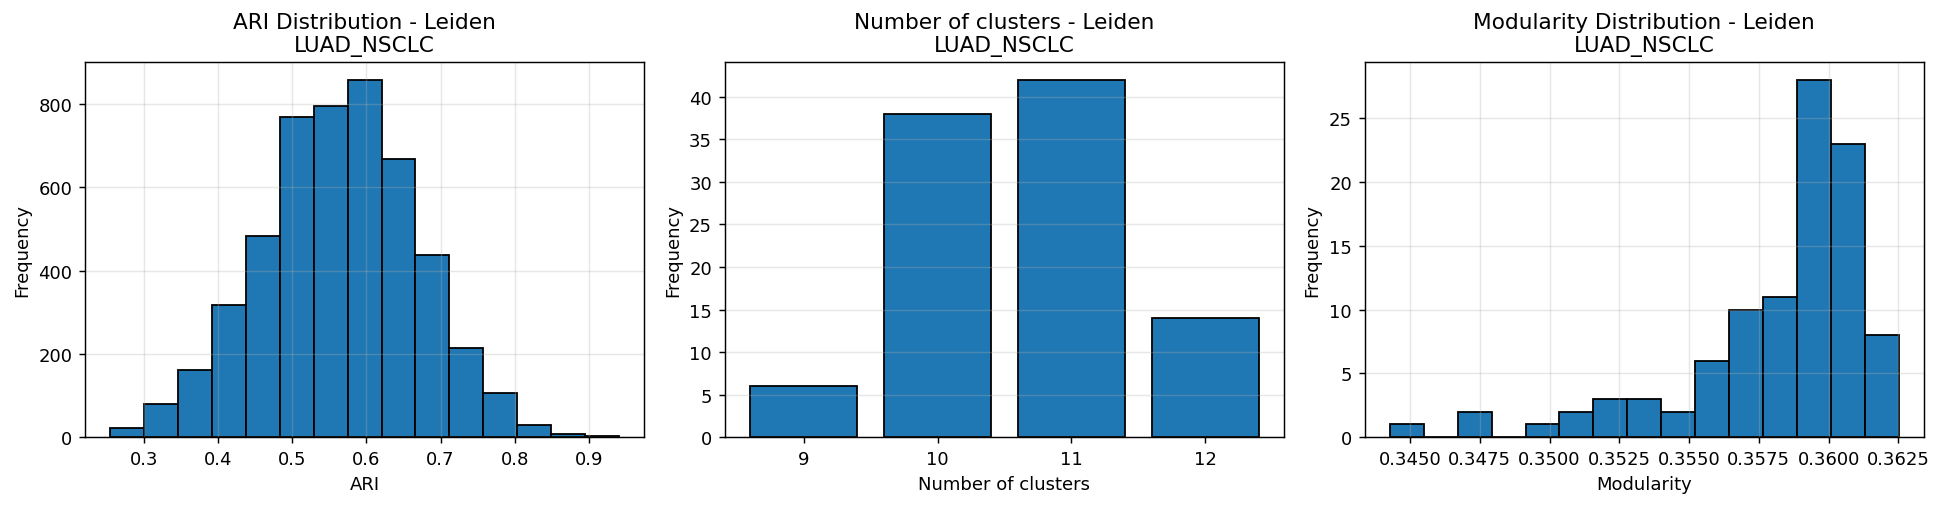

[LUAD_NSCLC] Plot salvato in: data_lung\networks_by_oncotree_groups\leiden_by_oncotree_groups\leiden_stability_plots_LUAD_NSCLC.png

Graph analyzed: LUSC_NSCLC (LUSC+NSCLC)
Nodes: 111 | Edges: 287
Density: 0.0470
Contains KRAS: True

=== Leiden Stability - ARI ===
Mean ARI: 0.8915
Std ARI: 0.0705
Min ARI: 0.7169
Max ARI: 1.0000

=== Leiden Modularity ===
Mean modularity: 0.5915
Std modularity: 0.0014
Min modularity: 0.5880
Max modularity: 0.5929

=== Number of clusters frequency ===


,Oncotree_Group,Included_Oncotree_Codes,Algorithm,Num_clusters,Frequency,Percentage
0,LUSC_NSCLC,LUSC+NSCLC,Leiden,7,54,54.0
1,LUSC_NSCLC,LUSC+NSCLC,Leiden,8,46,46.0



Most frequent Leiden partition: 7 clusters (54/100 runs, 54.0%)
Best Leiden partition by modularity: 7 clusters, seed=2, modularity=0.5929

Best partition preview:


,Oncotree_Group,Included_Oncotree_Codes,Gene,Leiden_cluster,Best_seed,Best_modularity
0,LUSC_NSCLC,LUSC+NSCLC,CDKN2Ap14ARF,0,2,0.592935
1,LUSC_NSCLC,LUSC+NSCLC,CDKN2Ap16INK4A,0,2,0.592935
2,LUSC_NSCLC,LUSC+NSCLC,CDKN2B,0,2,0.592935
3,LUSC_NSCLC,LUSC+NSCLC,CDKN2A,0,2,0.592935
4,LUSC_NSCLC,LUSC+NSCLC,DCUN1D1,1,2,0.592935
5,LUSC_NSCLC,LUSC+NSCLC,SOX2,1,2,0.592935
6,LUSC_NSCLC,LUSC+NSCLC,EIF4A2,1,2,0.592935
7,LUSC_NSCLC,LUSC+NSCLC,MAP3K13,1,2,0.592935
8,LUSC_NSCLC,LUSC+NSCLC,CCND1,5,2,0.592935
9,LUSC_NSCLC,LUSC+NSCLC,FGF19,5,2,0.592935


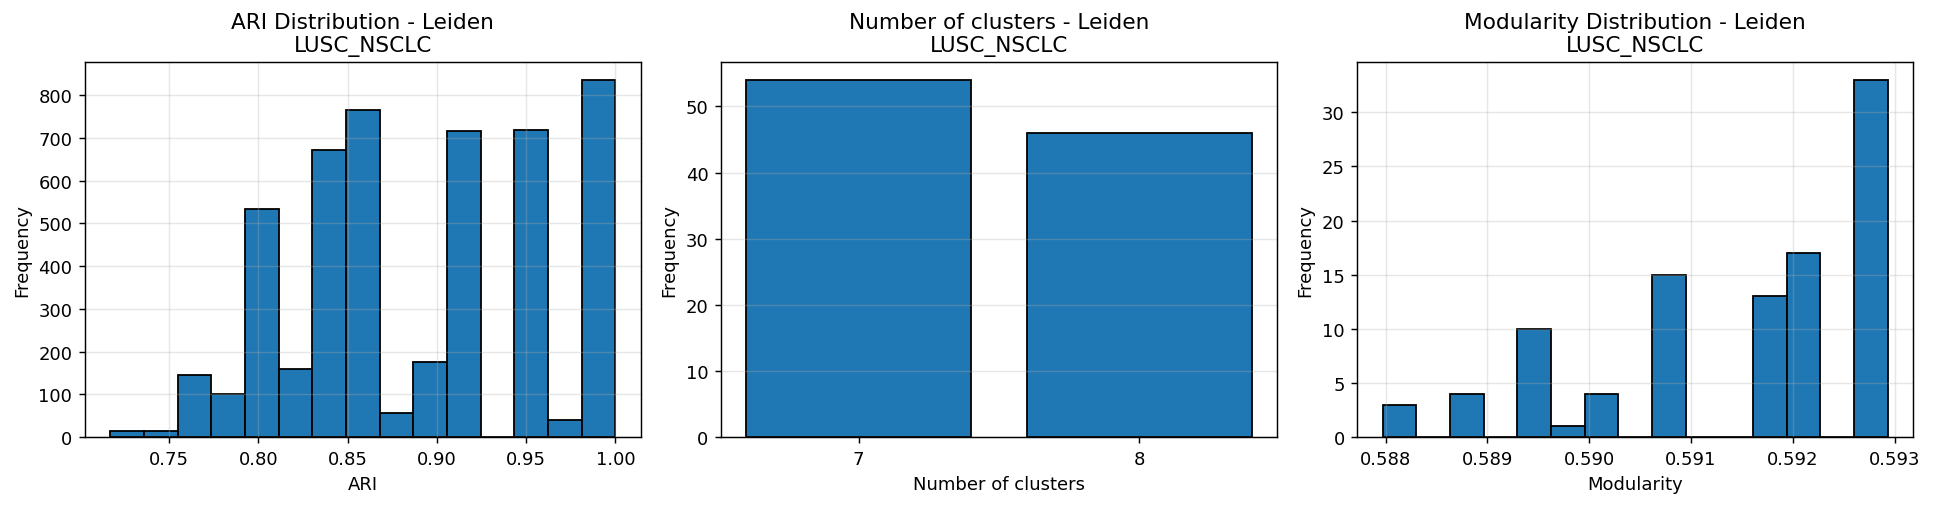

[LUSC_NSCLC] Plot salvato in: data_lung\networks_by_oncotree_groups\leiden_by_oncotree_groups\leiden_stability_plots_LUSC_NSCLC.png

Leiden analysis completed for these Oncotree groups:
['LUAD_NSCLC', 'LUSC_NSCLC']

Combined Leiden summary:


,Oncotree_Group,Included_Oncotree_Codes,Algorithm,Nodes,Edges,Density,Contains_KRAS,Resolution,Runs,Mean_ARI,...,Mean_modularity,Std_modularity,Min_modularity,Max_modularity,Best_seed,Best_modularity,Best_num_clusters,Most_frequent_num_clusters,Most_frequent_cluster_count_frequency,Most_frequent_cluster_count_percentage
0,LUAD_NSCLC,LUAD+NSCLC,Leiden,359,2774,0.043168,True,1.0,100,0.563498,...,0.358265,0.003375,0.344282,0.362508,78,0.362508,11,11,42,42.0
1,LUSC_NSCLC,LUSC+NSCLC,Leiden,111,287,0.047011,True,1.0,100,0.891500,...,0.591501,0.001437,0.587971,0.592935,2,0.592935,7,7,54,54.0



Combined Leiden cluster frequency:


,Oncotree_Group,Included_Oncotree_Codes,Algorithm,Num_clusters,Frequency,Percentage
0,LUAD_NSCLC,LUAD+NSCLC,Leiden,9,6,6.0
1,LUAD_NSCLC,LUAD+NSCLC,Leiden,10,38,38.0
2,LUAD_NSCLC,LUAD+NSCLC,Leiden,11,42,42.0
3,LUAD_NSCLC,LUAD+NSCLC,Leiden,12,14,14.0
4,LUSC_NSCLC,LUSC+NSCLC,Leiden,7,54,54.0
5,LUSC_NSCLC,LUSC+NSCLC,Leiden,8,46,46.0



Combined best partitions preview:


,Oncotree_Group,Included_Oncotree_Codes,Gene,Leiden_cluster,Best_seed,Best_modularity
0,LUAD_NSCLC,LUAD+NSCLC,CDKN2Ap14ARF,4,78,0.362508
1,LUAD_NSCLC,LUAD+NSCLC,CDKN2Ap16INK4A,4,78,0.362508
2,LUAD_NSCLC,LUAD+NSCLC,CDKN2B,4,78,0.362508
3,LUAD_NSCLC,LUAD+NSCLC,CDKN2A,4,78,0.362508
4,LUAD_NSCLC,LUAD+NSCLC,NFKBIA,6,78,0.362508
5,LUAD_NSCLC,LUAD+NSCLC,NKX2-1,6,78,0.362508
6,LUAD_NSCLC,LUAD+NSCLC,FOXA1,6,78,0.362508
7,LUAD_NSCLC,LUAD+NSCLC,ALK,9,78,0.362508
8,LUAD_NSCLC,LUAD+NSCLC,EML4,9,78,0.362508
9,LUAD_NSCLC,LUAD+NSCLC,KEAP1,1,78,0.362508


In [7]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from collections import Counter
from pathlib import Path

try:
    import igraph as ig
    import leidenalg
except ImportError as e:
    raise ImportError(
        "Per usare Leiden devi installare 'igraph' e 'leidenalg'. "
        "Esempio: pip install python-igraph leidenalg"
    ) from e


# ============================================================
# PARAMETRI LEIDEN
# ============================================================

n_runs = 100
seeds = list(range(n_runs))
resolution_parameter = 1.0

# Se True, fa Leiden solo sui grafi che contengono KRAS.
# Nel tuo caso è coerente, perché stai usando G_kras / KRAS subgraph.
require_kras = True

leiden_output_dir = output_dir / "leiden_by_oncotree_groups"
leiden_output_dir.mkdir(exist_ok=True)

# Gruppi da analizzare
target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}


# ============================================================
# FUNZIONI DI SUPPORTO
# ============================================================

def cluster_frequency_df(num_clusters, algorithm_name, group_name, n_runs):
    freq = Counter(num_clusters)

    readable_group_name = group_labels.get(group_name, group_name)

    df = (
        pd.DataFrame({
            "Oncotree_Group": group_name,
            "Included_Oncotree_Codes": readable_group_name,
            "Algorithm": algorithm_name,
            "Num_clusters": list(freq.keys()),
            "Frequency": list(freq.values())
        })
        .sort_values("Num_clusters")
        .reset_index(drop=True)
    )

    df["Percentage"] = (df["Frequency"] / n_runs * 100).round(2)

    return df


def compute_pairwise_ari(partitions):
    ari_scores = []

    for i in range(len(partitions)):
        for j in range(i + 1, len(partitions)):
            ari = adjusted_rand_score(partitions[i], partitions[j])
            ari_scores.append(ari)

    return np.array(ari_scores)


def run_leiden_stability_for_graph(G_test, group_name):
    """
    Esegue Leiden n volte sul grafo di un gruppo Oncotree aggregato.

    Gruppi:
    - LUAD_NSCLC = LUAD + NSCLC
    - LUSC_NSCLC = LUSC + NSCLC

    Calcola:
    - stabilità tramite ARI
    - modularity
    - frequenza del numero di cluster
    - partizione migliore
    """

    readable_group_name = group_labels.get(group_name, group_name)

    if G_test is None:
        print(f"[{group_name}] Saltato: grafo None.")
        return None

    if G_test.number_of_nodes() == 0 or G_test.number_of_edges() == 0:
        print(f"[{group_name}] Saltato: grafo vuoto o senza edges.")
        return None

    has_kras = any(str(n).upper() == "KRAS" for n in G_test.nodes())

    if require_kras and not has_kras:
        print(f"[{group_name}] Saltato: KRAS non presente nel grafo.")
        return None

    print("\n" + "=" * 80)
    print(f"Graph analyzed: {group_name} ({readable_group_name})")
    print(f"Nodes: {G_test.number_of_nodes()} | Edges: {G_test.number_of_edges()}")
    print(f"Density: {nx.density(G_test):.4f}")
    print(f"Contains KRAS: {has_kras}")

    node_list = list(G_test.nodes())

    # ============================================================
    # CONVERSIONE NETWORKX -> IGRAPH
    # ============================================================

    node_to_idx = {
        node: i
        for i, node in enumerate(node_list)
    }

    edges = []
    weights = []

    for u, v, data in G_test.edges(data=True):
        edges.append((node_to_idx[u], node_to_idx[v]))
        weights.append(float(data.get("log2_or", 1.0)))

    g_ig = ig.Graph(
        n=len(node_list),
        edges=edges,
        directed=False
    )

    g_ig.vs["name"] = node_list
    g_ig.es["weight"] = weights

    # ============================================================
    # LEIDEN MULTIPLE RUNS
    # ============================================================

    partitions_leiden = []
    num_clusters_leiden = []
    modularity_leiden = []
    membership_tables = []

    for seed in seeds:
        partition = leidenalg.find_partition(
            g_ig,
            leidenalg.RBConfigurationVertexPartition,
            weights=g_ig.es["weight"],
            resolution_parameter=resolution_parameter,
            seed=seed
        )

        labels = list(partition.membership)

        modularity_value = g_ig.modularity(
            labels,
            weights=g_ig.es["weight"]
        )

        partitions_leiden.append(labels)
        num_clusters_leiden.append(len(set(labels)))
        modularity_leiden.append(modularity_value)

        tmp_membership = pd.DataFrame({
            "Oncotree_Group": group_name,
            "Included_Oncotree_Codes": readable_group_name,
            "Seed": seed,
            "Gene": node_list,
            "Cluster": labels
        })

        membership_tables.append(tmp_membership)

    # ============================================================
    # ARI LEIDEN
    # ============================================================

    ari_scores_leiden = compute_pairwise_ari(partitions_leiden)

    # ============================================================
    # FREQUENCY TABLE
    # ============================================================

    cluster_freq_leiden_df = cluster_frequency_df(
        num_clusters=num_clusters_leiden,
        algorithm_name="Leiden",
        group_name=group_name,
        n_runs=n_runs
    )

    # ============================================================
    # BEST PARTITION
    # ============================================================

    best_run_idx = int(np.argmax(modularity_leiden))
    best_seed = seeds[best_run_idx]
    best_modularity = modularity_leiden[best_run_idx]
    best_labels = partitions_leiden[best_run_idx]

    best_partition_df = pd.DataFrame({
        "Oncotree_Group": group_name,
        "Included_Oncotree_Codes": readable_group_name,
        "Gene": node_list,
        "Leiden_cluster": best_labels,
        "Best_seed": best_seed,
        "Best_modularity": best_modularity
    })

    most_common_leiden = cluster_freq_leiden_df.sort_values(
        ["Frequency", "Num_clusters"],
        ascending=[False, True]
    ).iloc[0]

    # ============================================================
    # SUMMARY
    # ============================================================

    summary_row = {
        "Oncotree_Group": group_name,
        "Included_Oncotree_Codes": readable_group_name,
        "Algorithm": "Leiden",
        "Nodes": G_test.number_of_nodes(),
        "Edges": G_test.number_of_edges(),
        "Density": nx.density(G_test),
        "Contains_KRAS": has_kras,
        "Resolution": resolution_parameter,
        "Runs": n_runs,
        "Mean_ARI": ari_scores_leiden.mean() if len(ari_scores_leiden) > 0 else np.nan,
        "Std_ARI": ari_scores_leiden.std() if len(ari_scores_leiden) > 0 else np.nan,
        "Min_ARI": ari_scores_leiden.min() if len(ari_scores_leiden) > 0 else np.nan,
        "Max_ARI": ari_scores_leiden.max() if len(ari_scores_leiden) > 0 else np.nan,
        "Mean_modularity": np.mean(modularity_leiden),
        "Std_modularity": np.std(modularity_leiden),
        "Min_modularity": np.min(modularity_leiden),
        "Max_modularity": np.max(modularity_leiden),
        "Best_seed": best_seed,
        "Best_modularity": best_modularity,
        "Best_num_clusters": len(set(best_labels)),
        "Most_frequent_num_clusters": int(most_common_leiden["Num_clusters"]),
        "Most_frequent_cluster_count_frequency": int(most_common_leiden["Frequency"]),
        "Most_frequent_cluster_count_percentage": float(most_common_leiden["Percentage"])
    }

    summary_df = pd.DataFrame([summary_row])

    # ============================================================
    # PRINT RESULTS
    # ============================================================

    print("\n=== Leiden Stability - ARI ===")
    print(f"Mean ARI: {summary_row['Mean_ARI']:.4f}")
    print(f"Std ARI: {summary_row['Std_ARI']:.4f}")
    print(f"Min ARI: {summary_row['Min_ARI']:.4f}")
    print(f"Max ARI: {summary_row['Max_ARI']:.4f}")

    print("\n=== Leiden Modularity ===")
    print(f"Mean modularity: {summary_row['Mean_modularity']:.4f}")
    print(f"Std modularity: {summary_row['Std_modularity']:.4f}")
    print(f"Min modularity: {summary_row['Min_modularity']:.4f}")
    print(f"Max modularity: {summary_row['Max_modularity']:.4f}")

    print("\n=== Number of clusters frequency ===")

    try:
        display(cluster_freq_leiden_df)
    except NameError:
        print(cluster_freq_leiden_df)

    print(
        f"\nMost frequent Leiden partition: "
        f"{int(most_common_leiden['Num_clusters'])} clusters "
        f"({int(most_common_leiden['Frequency'])}/{n_runs} runs, "
        f"{most_common_leiden['Percentage']}%)"
    )

    print(
        f"Best Leiden partition by modularity: "
        f"{len(set(best_labels))} clusters, "
        f"seed={best_seed}, "
        f"modularity={best_modularity:.4f}"
    )

    print("\nBest partition preview:")

    try:
        display(best_partition_df.head(20))
    except NameError:
        print(best_partition_df.head(20))

    # ============================================================
    # SALVATAGGI
    # ============================================================

    summary_df.to_csv(
        leiden_output_dir / f"leiden_summary_{group_name}.csv",
        index=False
    )

    cluster_freq_leiden_df.to_csv(
        leiden_output_dir / f"leiden_cluster_frequency_{group_name}.csv",
        index=False
    )

    best_partition_df.to_csv(
        leiden_output_dir / f"leiden_best_partition_{group_name}.csv",
        index=False
    )

    all_memberships_df = pd.concat(
        membership_tables,
        ignore_index=True
    )

    all_memberships_df.to_csv(
        leiden_output_dir / f"leiden_all_memberships_{group_name}.csv",
        index=False
    )

    # ============================================================
    # PLOTS
    # ============================================================

    fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=130)

    axes[0].hist(
        ari_scores_leiden,
        bins=15,
        edgecolor="black"
    )
    axes[0].set_title(f"ARI Distribution - Leiden\n{group_name}")
    axes[0].set_xlabel("ARI")
    axes[0].set_ylabel("Frequency")
    axes[0].grid(alpha=0.3)

    axes[1].bar(
        cluster_freq_leiden_df["Num_clusters"],
        cluster_freq_leiden_df["Frequency"],
        edgecolor="black"
    )
    axes[1].set_title(f"Number of clusters - Leiden\n{group_name}")
    axes[1].set_xlabel("Number of clusters")
    axes[1].set_ylabel("Frequency")
    axes[1].set_xticks(cluster_freq_leiden_df["Num_clusters"])
    axes[1].grid(axis="y", alpha=0.3)

    axes[2].hist(
        modularity_leiden,
        bins=15,
        edgecolor="black"
    )
    axes[2].set_title(f"Modularity Distribution - Leiden\n{group_name}")
    axes[2].set_xlabel("Modularity")
    axes[2].set_ylabel("Frequency")
    axes[2].grid(alpha=0.3)

    plt.tight_layout()

    fig_path = leiden_output_dir / f"leiden_stability_plots_{group_name}.png"
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")

    plt.show()

    print(f"[{group_name}] Plot salvato in: {fig_path}")

    return {
        "summary": summary_df,
        "cluster_frequency": cluster_freq_leiden_df,
        "best_partition": best_partition_df,
        "all_memberships": all_memberships_df,
        "ari_scores": ari_scores_leiden,
        "modularity": np.array(modularity_leiden),
        "num_clusters": np.array(num_clusters_leiden)
    }


# ============================================================
# ESECUZIONE LEIDEN SOLO PER I DUE GRUPPI
# ============================================================

leiden_results_by_group = {}

for group_name in target_groups:

    if group_name not in graphs_by_group:
        print(f"[{group_name}] Non trovato in graphs_by_group. Saltato.")
        continue

    G = graphs_by_group[group_name]

    result = run_leiden_stability_for_graph(
        G_test=G,
        group_name=group_name
    )

    if result is not None:
        leiden_results_by_group[group_name] = result


# ============================================================
# TABELLE COMBINATE FINALI
# ============================================================

if len(leiden_results_by_group) > 0:

    leiden_summary_all = pd.concat(
        [res["summary"] for res in leiden_results_by_group.values()],
        ignore_index=True
    )

    leiden_cluster_frequency_all = pd.concat(
        [res["cluster_frequency"] for res in leiden_results_by_group.values()],
        ignore_index=True
    )

    leiden_best_partitions_all = pd.concat(
        [res["best_partition"] for res in leiden_results_by_group.values()],
        ignore_index=True
    )

    leiden_all_memberships_all = pd.concat(
        [res["all_memberships"] for res in leiden_results_by_group.values()],
        ignore_index=True
    )

    leiden_summary_all.to_csv(
        leiden_output_dir / "leiden_summary_all_oncotree_groups.csv",
        index=False
    )

    leiden_cluster_frequency_all.to_csv(
        leiden_output_dir / "leiden_cluster_frequency_all_oncotree_groups.csv",
        index=False
    )

    leiden_best_partitions_all.to_csv(
        leiden_output_dir / "leiden_best_partitions_all_oncotree_groups.csv",
        index=False
    )

    leiden_all_memberships_all.to_csv(
        leiden_output_dir / "leiden_all_memberships_all_oncotree_groups.csv",
        index=False
    )

    print("\n" + "=" * 80)
    print("Leiden analysis completed for these Oncotree groups:")
    print(list(leiden_results_by_group.keys()))

    print("\nCombined Leiden summary:")

    try:
        display(leiden_summary_all)
    except NameError:
        print(leiden_summary_all)

    print("\nCombined Leiden cluster frequency:")

    try:
        display(leiden_cluster_frequency_all)
    except NameError:
        print(leiden_cluster_frequency_all)

    print("\nCombined best partitions preview:")

    try:
        display(leiden_best_partitions_all.head(30))
    except NameError:
        print(leiden_best_partitions_all.head(30))

else:
    leiden_summary_all = pd.DataFrame()
    leiden_cluster_frequency_all = pd.DataFrame()
    leiden_best_partitions_all = pd.DataFrame()
    leiden_all_memberships_all = pd.DataFrame()

    print("Nessun grafo valido per Leiden.")


# ============================================================
# ALIAS OPZIONALI PER COMPATIBILITÀ CON CODICE SUCCESSIVO
# ============================================================

leiden_results_by_oncotree = leiden_results_by_group

***
## DATA ENRICHMENT: GENE ONTOLOGY, PATHWAYS, LITERATURE

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# g:Profiler enrichment analysis
# Leiden clusters - Oncotree groups oriented
# LUAD + NSCLC
# LUSC + NSCLC
# ============================================================

try:
    from gprofiler import GProfiler
except Exception as e:
    raise ImportError(
        "gprofiler-official non installato. "
        "Esegui: pip install gprofiler-official"
    ) from e


# ============================================================
# PARAMETRI
# ============================================================

sources = ["GO:BP", "REAC", "KEGG"]
alpha = 0.05
top_n_terms = 5

gprofiler_output_dir = output_dir / "gprofiler_leiden_by_oncotree_groups"
gprofiler_output_dir.mkdir(exist_ok=True)

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}


# ============================================================
# RECUPERO BEST PARTITIONS LEIDEN PER GRUPPI ONCOTREE
# ============================================================

leiden_partitions_by_group = {}

# Caso 1: dizionario prodotto dalla cella Leiden per gruppi
if (
        "leiden_results_by_group" in globals()
        and isinstance(leiden_results_by_group, dict)
        and len(leiden_results_by_group) > 0
):
    for group_name, res in leiden_results_by_group.items():

        if group_name not in target_groups:
            continue

        if (
                isinstance(res, dict)
                and "best_partition" in res
                and isinstance(res["best_partition"], pd.DataFrame)
                and not res["best_partition"].empty
        ):
            leiden_partitions_by_group[group_name] = res["best_partition"].copy()

# Caso 2: hai ancora l'alias leiden_results_by_oncotree = leiden_results_by_group
elif (
        "leiden_results_by_oncotree" in globals()
        and isinstance(leiden_results_by_oncotree, dict)
        and len(leiden_results_by_oncotree) > 0
):
    for group_name, res in leiden_results_by_oncotree.items():

        if group_name not in target_groups:
            continue

        if (
                isinstance(res, dict)
                and "best_partition" in res
                and isinstance(res["best_partition"], pd.DataFrame)
                and not res["best_partition"].empty
        ):
            leiden_partitions_by_group[group_name] = res["best_partition"].copy()

# Caso 3: hai solo la tabella combinata finale
elif (
        "leiden_best_partitions_all" in globals()
        and isinstance(leiden_best_partitions_all, pd.DataFrame)
        and not leiden_best_partitions_all.empty
):

    if "Oncotree_Group" in leiden_best_partitions_all.columns:
        group_col = "Oncotree_Group"
    elif "Oncotree Code" in leiden_best_partitions_all.columns:
        group_col = "Oncotree Code"
    else:
        raise ValueError(
            "leiden_best_partitions_all deve contenere 'Oncotree_Group' "
            "oppure 'Oncotree Code'."
        )

    required_cols = {group_col, "Gene", "Leiden_cluster"}
    missing_cols = required_cols - set(leiden_best_partitions_all.columns)

    if missing_cols:
        raise ValueError(
            f"leiden_best_partitions_all non contiene le colonne richieste: {missing_cols}"
        )

    for group_name, df_part in leiden_best_partitions_all.groupby(group_col):

        if group_name not in target_groups:
            continue

        leiden_partitions_by_group[group_name] = df_part.copy()

else:
    raise ValueError(
        "Nessuna best partition Leiden disponibile. "
        "Esegui prima la cella Leiden per i gruppi LUAD_NSCLC e LUSC_NSCLC."
    )


print("Best partitions Leiden disponibili per i gruppi:")
print(list(leiden_partitions_by_group.keys()))


# ============================================================
# RECUPERO HUB TABLE PER GRUPPI ONCOTREE
# ============================================================

hub_tables_available = {}

# Caso 1: dizionario prodotto dalla cella hub metrics per gruppi
if (
        "hub_tables_by_group" in globals()
        and isinstance(hub_tables_by_group, dict)
        and len(hub_tables_by_group) > 0
):
    for group_name, ht in hub_tables_by_group.items():

        if group_name not in target_groups:
            continue

        if isinstance(ht, pd.DataFrame) and not ht.empty:
            hub_tables_available[group_name] = ht.copy()

# Caso 2: hai ancora l'alias hub_tables_by_oncotree = hub_tables_by_group
elif (
        "hub_tables_by_oncotree" in globals()
        and isinstance(hub_tables_by_oncotree, dict)
        and len(hub_tables_by_oncotree) > 0
):
    for group_name, ht in hub_tables_by_oncotree.items():

        if group_name not in target_groups:
            continue

        if isinstance(ht, pd.DataFrame) and not ht.empty:
            hub_tables_available[group_name] = ht.copy()

# Caso 3: tabella combinata prodotta dalla cella hub metrics
elif (
        "all_hub_tables" in globals()
        and isinstance(all_hub_tables, pd.DataFrame)
        and not all_hub_tables.empty
):

    if "Oncotree_Group" in all_hub_tables.columns:
        group_col = "Oncotree_Group"
    elif "Oncotree Code" in all_hub_tables.columns:
        group_col = "Oncotree Code"
    else:
        raise ValueError(
            "all_hub_tables deve contenere 'Oncotree_Group' oppure 'Oncotree Code'."
        )

    required_cols = {group_col, "Gene"}
    missing_cols = required_cols - set(all_hub_tables.columns)

    if missing_cols:
        raise ValueError(
            f"all_hub_tables non contiene le colonne richieste: {missing_cols}"
        )

    for group_name, ht in all_hub_tables.groupby(group_col):

        if group_name not in target_groups:
            continue

        hub_tables_available[group_name] = ht.copy()

else:
    raise ValueError(
        "Nessuna hub table disponibile. "
        "Esegui prima la cella delle hub metrics per i gruppi Oncotree."
    )


print("\nHub tables disponibili per i gruppi:")
print(list(hub_tables_available.keys()))


# ============================================================
# FUNZIONI DI SUPPORTO
# ============================================================

def detect_hubscore_column(hub_table):
    """
    Trova la colonna HubScore corretta nella hub table.
    """

    possible_cols = [
        "HubScore",
        "HubScore_1over5",
        "HubScore_equal"
    ]

    for col in possible_cols:
        if col in hub_table.columns:
            return col

    raise ValueError(
        "Nessuna colonna HubScore trovata nella hub table. "
        "Controlla di aver eseguito la cella delle hub metrics."
    )


def get_best_from_source(df, source_name):
    """
    Estrae il miglior termine per una specifica sorgente:
    GO:BP, KEGG o REAC.
    """

    if df is None or df.empty:
        return "-", pd.NA

    if "source" not in df.columns or "p_value" not in df.columns:
        return "-", pd.NA

    df_source = df[df["source"] == source_name].sort_values("p_value")

    if df_source.empty:
        return "-", pd.NA

    best = df_source.iloc[0]

    return best.get("name", "-"), best.get("p_value", pd.NA)


def safe_is_significant(p_value, alpha=0.05):
    """
    Evita errori con pd.NA / nan.
    """

    if pd.isna(p_value):
        return False

    try:
        return float(p_value) <= alpha
    except Exception:
        return False


def compute_confidence_score(best_p, cluster_size, significant_terms):
    """
    Confidence score euristico per valutare quanto è biologicamente interpretabile un cluster.
    """

    if pd.isna(best_p) or best_p <= 0:
        p_score = 0.0
    else:
        p_score = min(-np.log10(float(best_p)) / 10.0, 1.0)

    size_score = min(cluster_size / 15.0, 1.0)
    sig_score = min(significant_terms / 5.0, 1.0)

    confidence_score = (
            0.45 * p_score
            + 0.35 * sig_score
            + 0.20 * size_score
    )

    if confidence_score >= 0.75 and significant_terms >= 3:
        confidence_label = "Strong"
    elif confidence_score >= 0.45 and significant_terms >= 1:
        confidence_label = "Moderate"
    else:
        confidence_label = "Weak"

    return round(float(confidence_score), 3), confidence_label


# ============================================================
# g:Profiler
# ============================================================

gp = GProfiler(return_dataframe=True)

summary_rows_all = []
confidence_rows_all = []
terms_all = []
genes_by_cluster_all = []

terms_by_group_cluster = {}
cluster_gene_dict_by_group = {}


# ============================================================
# RUN ENRICHMENT PER GRUPPO ONCOTREE E PER LEIDEN CLUSTER
# ============================================================

for group_name, leiden_partition_df in leiden_partitions_by_group.items():

    readable_group_name = group_labels.get(group_name, group_name)

    print("\n" + "=" * 100)
    print(f"ONCOTREE GROUP: {group_name} ({readable_group_name})")

    if group_name not in hub_tables_available:
        print(f"[{group_name}] Saltato: hub table non disponibile.")
        continue

    hub_table_current = hub_tables_available[group_name].copy()

    required_partition_cols = {"Gene", "Leiden_cluster"}
    missing_partition_cols = required_partition_cols - set(leiden_partition_df.columns)

    if missing_partition_cols:
        print(
            f"[{group_name}] Saltato: colonne mancanti nella Leiden partition: "
            f"{missing_partition_cols}"
        )
        continue

    if "Gene" not in hub_table_current.columns:
        print(f"[{group_name}] Saltato: colonna Gene mancante nella hub table.")
        continue

    score_col = detect_hubscore_column(hub_table_current)

    hub_rank_df = hub_table_current[["Gene", score_col]].copy()
    hub_rank_df["Gene"] = hub_rank_df["Gene"].astype(str)

    hubscore_map = dict(
        zip(
            hub_rank_df["Gene"],
            hub_rank_df[score_col]
        )
    )

    leiden_partition_df = leiden_partition_df.copy()
    leiden_partition_df["Gene"] = leiden_partition_df["Gene"].astype(str)

    # ------------------------------------------------------------
    # Build Leiden cluster gene dict per gruppo Oncotree
    # ------------------------------------------------------------

    cluster_gene_dict = {}

    for _, row in leiden_partition_df.iterrows():
        gene = str(row["Gene"])
        cid = row["Leiden_cluster"]

        if pd.notna(cid):
            cluster_gene_dict.setdefault(int(cid), []).append(gene)

    # Ordina i geni di ogni cluster in base all'HubScore dello stesso gruppo
    cluster_gene_dict = {
        cid: sorted(
            list(set(genes)),
            key=lambda g: hubscore_map.get(str(g), -np.inf),
            reverse=True
        )
        for cid, genes in cluster_gene_dict.items()
    }

    cluster_gene_dict_by_group[group_name] = cluster_gene_dict
    terms_by_group_cluster[group_name] = {}

    print(f"Leiden clusters trovati per {group_name}: {len(cluster_gene_dict)}")

    # ------------------------------------------------------------
    # Run g:Profiler per Leiden cluster
    # ------------------------------------------------------------

    for cid, genes in sorted(cluster_gene_dict.items()):

        genes = [
            str(g)
            for g in genes
            if pd.notna(g)
        ]

        cluster_size = len(genes)

        genes_with_scores = pd.DataFrame({
            "Oncotree_Group": group_name,
            "Included_Oncotree_Codes": readable_group_name,
            "Cluster": cid,
            "Gene": genes,
            score_col: [
                hubscore_map.get(g, np.nan)
                for g in genes
            ]
        }).sort_values(
            score_col,
            ascending=False
        ).reset_index(drop=True)

        genes_by_cluster_all.append(genes_with_scores)

        if cluster_size < 2:
            terms_by_group_cluster[group_name][cid] = pd.DataFrame()

            summary_rows_all.append({
                "Oncotree_Group": group_name,
                "Included_Oncotree_Codes": readable_group_name,
                "Cluster": cid,
                "Num_genes": cluster_size,

                "Best_overall_term": "Too few genes",
                "Best_overall_source": "-",
                "Best_overall_p_value": pd.NA,

                "Best_GO_BP_term": "-",
                "Best_GO_BP_p_value": pd.NA,

                "Best_KEGG_term": "-",
                "Best_KEGG_p_value": pd.NA,

                "Best_REAC_term": "-",
                "Best_REAC_p_value": pd.NA,

                "Significant_p<=0.05": False,
            })

            continue

        try:
            res = gp.profile(
                organism="hsapiens",
                query=genes,
                ordered=False,
                no_evidences=False,
                significance_threshold_method="fdr",
                sources=sources,
            )

            if res is None or res.empty:
                terms_by_group_cluster[group_name][cid] = pd.DataFrame()

                summary_rows_all.append({
                    "Oncotree_Group": group_name,
                    "Included_Oncotree_Codes": readable_group_name,
                    "Cluster": cid,
                    "Num_genes": cluster_size,

                    "Best_overall_term": "No terms returned",
                    "Best_overall_source": "-",
                    "Best_overall_p_value": pd.NA,

                    "Best_GO_BP_term": "-",
                    "Best_GO_BP_p_value": pd.NA,

                    "Best_KEGG_term": "-",
                    "Best_KEGG_p_value": pd.NA,

                    "Best_REAC_term": "-",
                    "Best_REAC_p_value": pd.NA,

                    "Significant_p<=0.05": False,
                })

                continue

            keep_cols = [
                c for c in [
                    "source",
                    "native",
                    "name",
                    "p_value",
                    "term_size",
                    "query_size",
                    "intersection_size"
                ]
                if c in res.columns
            ]

            out = res[keep_cols].copy()
            out = out.sort_values("p_value", ascending=True)
            out["significant"] = out["p_value"] <= alpha
            out["Oncotree_Group"] = group_name
            out["Included_Oncotree_Codes"] = readable_group_name
            out["Cluster"] = cid
            out["Num_genes_cluster"] = cluster_size

            terms_by_group_cluster[group_name][cid] = out
            terms_all.append(out)

            # ----------------------------------------------------
            # Best term per database/source
            # ----------------------------------------------------

            best_go_term, best_go_p = get_best_from_source(out, "GO:BP")
            best_kegg_term, best_kegg_p = get_best_from_source(out, "KEGG")
            best_reac_term, best_reac_p = get_best_from_source(out, "REAC")

            best_overall = out.iloc[0]
            best_overall_term = best_overall.get("name", "-")
            best_overall_source = best_overall.get("source", "-")
            best_overall_p = best_overall.get("p_value", pd.NA)

            summary_rows_all.append({
                "Oncotree_Group": group_name,
                "Included_Oncotree_Codes": readable_group_name,
                "Cluster": cid,
                "Num_genes": cluster_size,

                "Best_overall_term": best_overall_term,
                "Best_overall_source": best_overall_source,
                "Best_overall_p_value": best_overall_p,

                "Best_GO_BP_term": best_go_term,
                "Best_GO_BP_p_value": best_go_p,

                "Best_KEGG_term": best_kegg_term,
                "Best_KEGG_p_value": best_kegg_p,

                "Best_REAC_term": best_reac_term,
                "Best_REAC_p_value": best_reac_p,

                "Significant_p<=0.05": safe_is_significant(best_overall_p, alpha),
            })

        except Exception as ex:
            terms_by_group_cluster[group_name][cid] = pd.DataFrame()

            summary_rows_all.append({
                "Oncotree_Group": group_name,
                "Included_Oncotree_Codes": readable_group_name,
                "Cluster": cid,
                "Num_genes": cluster_size,

                "Best_overall_term": f"Error: {str(ex)}",
                "Best_overall_source": "-",
                "Best_overall_p_value": pd.NA,

                "Best_GO_BP_term": "-",
                "Best_GO_BP_p_value": pd.NA,

                "Best_KEGG_term": "-",
                "Best_KEGG_p_value": pd.NA,

                "Best_REAC_term": "-",
                "Best_REAC_p_value": pd.NA,

                "Significant_p<=0.05": False,
            })


# ============================================================
# SUMMARY TABLE
# ============================================================

summary_df = (
    pd.DataFrame(summary_rows_all)
    .sort_values(["Oncotree_Group", "Cluster"])
    .reset_index(drop=True)
)

print("\ng:Profiler enrichment summary for Leiden clusters by Oncotree groups")
print(f"Sources: {', '.join(sources)} | significance cutoff: p <= {alpha}")

try:
    display(summary_df)
except NameError:
    print(summary_df)


# ============================================================
# CONFIDENCE RANKING
# ============================================================

for group_name, cluster_gene_dict in cluster_gene_dict_by_group.items():

    readable_group_name = group_labels.get(group_name, group_name)

    for cid, genes in sorted(cluster_gene_dict.items()):

        cluster_size = len(genes)

        summary_row = summary_df[
            (summary_df["Oncotree_Group"] == group_name)
            & (summary_df["Cluster"] == cid)
            ]

        if summary_row.empty:
            best_p = np.nan
            best_term = "No result"
            best_source = "-"
            significant_terms = 0
        else:
            summary_row = summary_row.iloc[0]

            best_p = summary_row.get("Best_overall_p_value", np.nan)
            best_term = summary_row.get("Best_overall_term", "No result")
            best_source = summary_row.get("Best_overall_source", "-")

            terms_df = terms_by_group_cluster.get(
                group_name,
                {}
            ).get(
                cid,
                pd.DataFrame()
            )

            if (
                    isinstance(terms_df, pd.DataFrame)
                    and not terms_df.empty
                    and "significant" in terms_df.columns
            ):
                significant_terms = int(
                    terms_df["significant"].fillna(False).sum()
                )
            else:
                significant_terms = 0

        confidence_score, confidence_label = compute_confidence_score(
            best_p=best_p,
            cluster_size=cluster_size,
            significant_terms=significant_terms
        )

        confidence_rows_all.append({
            "Oncotree_Group": group_name,
            "Included_Oncotree_Codes": readable_group_name,
            "Cluster": cid,
            "Cluster_size": cluster_size,
            "Best_overall_term": best_term,
            "Best_overall_source": best_source,
            "Best_overall_p_value": best_p,
            "Significant_terms": significant_terms,
            "Confidence_score": confidence_score,
            "Confidence": confidence_label,
        })


confidence_df = (
    pd.DataFrame(confidence_rows_all)
    .sort_values(
        [
            "Oncotree_Group",
            "Confidence_score",
            "Significant_terms",
            "Cluster"
        ],
        ascending=[True, False, False, True]
    )
    .reset_index(drop=True)
)

print("\nConfidence ranking for Leiden cluster biological relevance by Oncotree groups")

try:
    display(confidence_df)
except NameError:
    print(confidence_df)


# ============================================================
# DETAILED ENRICHMENT PER GRUPPO ONCOTREE E CLUSTER
# ============================================================

print("\nLeiden clusters - top g:Profiler enrichment terms by Oncotree groups")

for group_name, cluster_gene_dict in cluster_gene_dict_by_group.items():

    readable_group_name = group_labels.get(group_name, group_name)

    print("\n" + "#" * 120)
    print(f"ONCOTREE GROUP: {group_name} ({readable_group_name})")
    print("#" * 120)

    hub_table_current = hub_tables_available[group_name].copy()
    score_col = detect_hubscore_column(hub_table_current)

    hub_rank_df = hub_table_current[["Gene", score_col]].copy()
    hub_rank_df["Gene"] = hub_rank_df["Gene"].astype(str)

    hubscore_map = dict(
        zip(
            hub_rank_df["Gene"],
            hub_rank_df[score_col]
        )
    )

    for cid in sorted(cluster_gene_dict.keys()):

        genes = cluster_gene_dict[cid]

        genes_with_scores = pd.DataFrame({
            "Gene": genes,
            score_col: [
                hubscore_map.get(g, np.nan)
                for g in genes
            ]
        }).sort_values(
            score_col,
            ascending=False
        ).reset_index(drop=True)

        print("\n" + "=" * 100)
        print(f"Oncotree Group: {group_name} ({readable_group_name}) | Leiden cluster: {cid}")
        print(f"Number of genes: {len(genes)}")
        print(f"Genes ordered by HubScore ({score_col}):")

        try:
            display(genes_with_scores)
        except NameError:
            print(genes_with_scores)

        dfc = terms_by_group_cluster.get(
            group_name,
            {}
        ).get(
            cid,
            pd.DataFrame()
        )

        if dfc is None or dfc.empty:
            print("\nNo enrichment terms returned.")
        else:
            print(f"\nTop {top_n_terms} enrichment terms:")

            try:
                display(dfc.head(top_n_terms))
            except NameError:
                print(dfc.head(top_n_terms))


# ============================================================
# SALVATAGGIO OUTPUT
# ============================================================

summary_file = gprofiler_output_dir / "gprofiler_summary_leiden_all_oncotree_groups.csv"
confidence_file = gprofiler_output_dir / "gprofiler_confidence_leiden_all_oncotree_groups.csv"
terms_file = gprofiler_output_dir / "gprofiler_terms_leiden_all_oncotree_groups.csv"
genes_file = gprofiler_output_dir / "leiden_cluster_genes_with_hubscore_all_oncotree_groups.csv"

summary_df.to_csv(summary_file, index=False)
confidence_df.to_csv(confidence_file, index=False)

if len(terms_all) > 0:
    terms_all_df = pd.concat(terms_all, ignore_index=True)
else:
    terms_all_df = pd.DataFrame()

terms_all_df.to_csv(terms_file, index=False)

if len(genes_by_cluster_all) > 0:
    genes_by_cluster_all_df = pd.concat(
        genes_by_cluster_all,
        ignore_index=True
    )
else:
    genes_by_cluster_all_df = pd.DataFrame()

genes_by_cluster_all_df.to_csv(genes_file, index=False)


# Salvataggi separati per gruppo Oncotree
for group_name in sorted(cluster_gene_dict_by_group.keys()):

    summary_sub = summary_df[
        summary_df["Oncotree_Group"] == group_name
        ].copy()

    confidence_sub = confidence_df[
        confidence_df["Oncotree_Group"] == group_name
        ].copy()

    summary_sub.to_csv(
        gprofiler_output_dir / f"gprofiler_summary_leiden_{group_name}.csv",
        index=False
    )

    confidence_sub.to_csv(
        gprofiler_output_dir / f"gprofiler_confidence_leiden_{group_name}.csv",
        index=False
    )

    if not terms_all_df.empty:
        terms_sub = terms_all_df[
            terms_all_df["Oncotree_Group"] == group_name
            ].copy()

        terms_sub.to_csv(
            gprofiler_output_dir / f"gprofiler_terms_leiden_{group_name}.csv",
            index=False
        )

    if not genes_by_cluster_all_df.empty:
        genes_sub = genes_by_cluster_all_df[
            genes_by_cluster_all_df["Oncotree_Group"] == group_name
            ].copy()

        genes_sub.to_csv(
            gprofiler_output_dir / f"leiden_cluster_genes_with_hubscore_{group_name}.csv",
            index=False
        )


print("\nOutput salvati in:")
print(gprofiler_output_dir)

print("\nFile principali:")
print(summary_file)
print(confidence_file)
print(terms_file)
print(genes_file)


# ============================================================
# INTERPRETAZIONE
# ============================================================

print("\nInterpretation:")
print("- L'analisi è stata eseguita separatamente per i due gruppi Oncotree aggregati.")
print("- I gruppi analizzati sono LUAD+NSCLC e LUSC+NSCLC.")
print("- Ogni cluster Leiden viene interpretato biologicamente con g:Profiler.")
print("- I geni dentro ogni cluster sono ordinati usando l'HubScore calcolato nello stesso gruppo.")
print("- GO:BP descrive processi biologici.")
print("- KEGG descrive pathway canonici o contesti tumorali.")
print("- Reactome descrive eventi molecolari/meccanicistici più specifici.")
print("- Confidence è una misura euristica basata su p-value, numero di termini significativi e dimensione del cluster.")


# ============================================================
# ALIAS OPZIONALI PER COMPATIBILITÀ CON CODICE SUCCESSIVO
# ============================================================

leiden_partitions_by_oncotree = leiden_partitions_by_group
terms_by_oncotree_cluster = terms_by_group_cluster
cluster_gene_dict_by_oncotree = cluster_gene_dict_by_group

Best partitions Leiden disponibili per i gruppi:
['LUAD_NSCLC', 'LUSC_NSCLC']

Hub tables disponibili per i gruppi:
['LUAD_NSCLC', 'LUSC_NSCLC']

ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
Leiden clusters trovati per LUAD_NSCLC: 11

ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
Leiden clusters trovati per LUSC_NSCLC: 7

g:Profiler enrichment summary for Leiden clusters by Oncotree groups
Sources: GO:BP, REAC, KEGG | significance cutoff: p <= 0.05


,Oncotree_Group,Included_Oncotree_Codes,Cluster,Num_genes,Best_overall_term,Best_overall_source,Best_overall_p_value,Best_GO_BP_term,Best_GO_BP_p_value,Best_KEGG_term,Best_KEGG_p_value,Best_REAC_term,Best_REAC_p_value,Significant_p<=0.05
0,LUAD_NSCLC,LUAD+NSCLC,0,93,response to stem cell factor,GO:BP,1.700892e-21,response to stem cell factor,1.700892e-21,MicroRNAs in cancer,0.0,Constitutive Signaling by Aberrant PI3K in Cancer,2.921550e-08,True
1,LUAD_NSCLC,LUAD+NSCLC,1,49,cellular response to stress,GO:BP,1.392927e-10,cellular response to stress,1.392927e-10,FoxO signaling pathway,0.000001,Disease,1.988321e-04,True
2,LUAD_NSCLC,LUAD+NSCLC,2,48,positive regulation of macromolecule metabolic...,GO:BP,2.388172e-19,positive regulation of macromolecule metabolic...,2.388172e-19,Pathways in cancer,0.000001,Generic Transcription Pathway,1.534099e-05,True
3,LUAD_NSCLC,LUAD+NSCLC,3,44,cell differentiation,GO:BP,3.839302e-12,cell differentiation,3.839302e-12,Pathways in cancer,0.0,Diseases of signal transduction by growth fact...,4.072886e-06,True
4,LUAD_NSCLC,LUAD+NSCLC,4,39,cellular response to stimulus,GO:BP,2.956015e-10,cellular response to stimulus,2.956015e-10,Pathways in cancer,0.0,Disease,1.024115e-03,True
5,LUAD_NSCLC,LUAD+NSCLC,5,23,regulation of developmental process,GO:BP,5.000039e-07,regulation of developmental process,5.000039e-07,Endometrial cancer,0.00001,ESR-mediated signaling,1.730522e-05,True
6,LUAD_NSCLC,LUAD+NSCLC,6,23,Pathways in cancer,KEGG,4.256690e-11,response to endogenous stimulus,3.077772e-10,Pathways in cancer,0.0,"PI5P, PP2A and IER3 Regulate PI3K/AKT Signaling",2.157487e-06,True
7,LUAD_NSCLC,LUAD+NSCLC,7,15,Signalling to p38 via RIT and RIN,REAC,2.382017e-03,attachment of spindle microtubules to kinetochore,2.478789e-02,Citrate cycle (TCA cycle),0.036985,Signalling to p38 via RIT and RIN,2.382017e-03,True
8,LUAD_NSCLC,LUAD+NSCLC,8,15,Signaling by FGFR3 in disease,REAC,3.785506e-04,regulation of cell population proliferation,3.557248e-03,Bladder cancer,0.002081,Signaling by FGFR3 in disease,3.785506e-04,True
9,LUAD_NSCLC,LUAD+NSCLC,9,7,Diseases of signal transduction by growth fact...,REAC,5.833321e-04,organelle fission,3.757634e-02,PD-L1 expression and PD-1 checkpoint pathway i...,0.02716,Diseases of signal transduction by growth fact...,5.833321e-04,True



Confidence ranking for Leiden cluster biological relevance by Oncotree groups


,Oncotree_Group,Included_Oncotree_Codes,Cluster,Cluster_size,Best_overall_term,Best_overall_source,Best_overall_p_value,Significant_terms,Confidence_score,Confidence
0,LUAD_NSCLC,LUAD+NSCLC,0,93,response to stem cell factor,GO:BP,1.700892e-21,1785,1.000,Strong
1,LUAD_NSCLC,LUAD+NSCLC,2,48,positive regulation of macromolecule metabolic...,GO:BP,2.388172e-19,1723,1.000,Strong
2,LUAD_NSCLC,LUAD+NSCLC,3,44,cell differentiation,GO:BP,3.839302e-12,1250,1.000,Strong
3,LUAD_NSCLC,LUAD+NSCLC,6,23,Pathways in cancer,KEGG,4.256690e-11,1241,1.000,Strong
4,LUAD_NSCLC,LUAD+NSCLC,1,49,cellular response to stress,GO:BP,1.392927e-10,1258,0.994,Strong
5,LUAD_NSCLC,LUAD+NSCLC,4,39,cellular response to stimulus,GO:BP,2.956015e-10,1233,0.979,Strong
6,LUAD_NSCLC,LUAD+NSCLC,5,23,regulation of developmental process,GO:BP,5.000039e-07,1268,0.834,Strong
7,LUAD_NSCLC,LUAD+NSCLC,8,15,Signaling by FGFR3 in disease,REAC,3.785506e-04,569,0.704,Moderate
8,LUAD_NSCLC,LUAD+NSCLC,7,15,Signalling to p38 via RIT and RIN,REAC,2.382017e-03,307,0.668,Moderate
9,LUAD_NSCLC,LUAD+NSCLC,9,7,Diseases of signal transduction by growth fact...,REAC,5.833321e-04,148,0.589,Moderate



Leiden clusters - top g:Profiler enrichment terms by Oncotree groups

########################################################################################################################
ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
########################################################################################################################

Oncotree Group: LUAD_NSCLC (LUAD+NSCLC) | Leiden cluster: 0
Number of genes: 93
Genes ordered by HubScore (HubScore):


,Gene,HubScore
0,PTPRT,0.999304
1,PTPRD,0.996518
2,NTRK3,0.985724
3,EPHA3,0.981198
4,ERBB4,0.977019
...,...,...
88,MSH2,0.187674
89,TSC1,0.186281
90,TOP1,0.135097
91,SOCS1,0.124652


... (67 outputs left out)

,Gene,HubScore
0,TERT,0.745495
1,ERBB4,0.644144
2,EGFR,0.396396
3,TRIP13,0.356982
4,SDHA,0.195946
5,RET,0.117117



Top 5 enrichment terms:


,source,native,name,p_value,term_size,query_size,intersection_size,significant,Oncotree_Group,Included_Oncotree_Codes,Cluster,Num_genes_cluster
0,GO:BP,GO:0048012,hepatocyte growth factor receptor signaling pa...,0.000036,61,6,3,True,LUSC_NSCLC,LUSC+NSCLC,6,6
1,GO:BP,GO:0036006,cellular response to macrophage colony-stimula...,0.000036,61,6,3,True,LUSC_NSCLC,LUSC+NSCLC,6,6
2,GO:BP,GO:0036216,cellular response to stem cell factor stimulus,0.000036,53,6,3,True,LUSC_NSCLC,LUSC+NSCLC,6,6
3,GO:BP,GO:0036323,vascular endothelial growth factor receptor-1 ...,0.000036,50,6,3,True,LUSC_NSCLC,LUSC+NSCLC,6,6
4,GO:BP,GO:0038109,Kit signaling pathway,0.000036,53,6,3,True,LUSC_NSCLC,LUSC+NSCLC,6,6



Output salvati in:
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups

File principali:
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups\gprofiler_summary_leiden_all_oncotree_groups.csv
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups\gprofiler_confidence_leiden_all_oncotree_groups.csv
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups\gprofiler_terms_leiden_all_oncotree_groups.csv
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups\leiden_cluster_genes_with_hubscore_all_oncotree_groups.csv

Interpretation:
- L'analisi è stata eseguita separatamente per i due gruppi Oncotree aggregati.
- I gruppi analizzati sono LUAD+NSCLC e LUSC+NSCLC.
- Ogni cluster Leiden viene interpretato biologicamente con g:Profiler.
- I geni dentro ogni cluster sono ordinati usando l'HubScore calcolato nello stesso gruppo.
- GO:BP descrive processi biologici.
- KEGG descrive pathway canonici o 

In [9]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# BEST SIGNIFICANT ENRICHMENT TERM PER LEIDEN CLUSTER
# Oncotree groups-oriented
# LUAD + NSCLC
# LUSC + NSCLC
# ============================================================

# Parametri
alpha = 0.05
max_hub_genes_to_show = 20  # cambia a None se vuoi mostrare tutti i geni

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

required_vars = [
    "terms_by_group_cluster",
    "cluster_gene_dict_by_group",
    "hub_tables_available",
    "detect_hubscore_column"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima la cella g:Profiler Leiden per gruppi Oncotree."
    )

# Se gprofiler_output_dir non esiste, lo creo in modo robusto
if "gprofiler_output_dir" not in globals():
    if "output_dir" in globals():
        gprofiler_output_dir = output_dir / "gprofiler_leiden_by_oncotree_groups"
    else:
        gprofiler_output_dir = (
                Path("data_lung")
                / "networks_by_oncotree_groups"
                / "gprofiler_leiden_by_oncotree_groups"
        )

gprofiler_output_dir.mkdir(parents=True, exist_ok=True)


def get_ordered_hub_genes_for_cluster(group_name, genes, max_genes=20):
    """
    Restituisce i geni del cluster ordinati per HubScore dello stesso gruppo Oncotree.
    Esempi:
    - LUAD_NSCLC = LUAD + NSCLC
    - LUSC_NSCLC = LUSC + NSCLC
    """

    if group_name not in hub_tables_available:
        return "Hub table not available"

    hub_table_current = hub_tables_available[group_name].copy()

    score_col = detect_hubscore_column(hub_table_current)

    hub_table_current["Gene"] = hub_table_current["Gene"].astype(str)

    hubscore_map = dict(
        zip(
            hub_table_current["Gene"],
            hub_table_current[score_col]
        )
    )

    ordered_genes = sorted(
        [str(g) for g in genes],
        key=lambda g: hubscore_map.get(g, -np.inf),
        reverse=True
    )

    labels = []

    genes_to_show = ordered_genes if max_genes is None else ordered_genes[:max_genes]

    for rank, gene in enumerate(genes_to_show, start=1):
        score = hubscore_map.get(gene, np.nan)

        if pd.notna(score):
            labels.append(f"{rank}. {gene} ({score:.3f})")
        else:
            labels.append(f"{rank}. {gene}")

    if max_genes is not None and len(ordered_genes) > max_genes:
        labels.append(f"... +{len(ordered_genes) - max_genes} genes")

    return " | ".join(labels)


best_term_rows = []

for group_name, cluster_gene_dict in cluster_gene_dict_by_group.items():

    if group_name not in target_groups:
        continue

    readable_group_name = group_labels.get(group_name, group_name)

    for cluster_id, genes in sorted(cluster_gene_dict.items()):

        genes = [str(g) for g in genes]
        num_genes = len(genes)

        hub_genes_ordered = get_ordered_hub_genes_for_cluster(
            group_name=group_name,
            genes=genes,
            max_genes=max_hub_genes_to_show
        )

        terms_df = (
            terms_by_group_cluster
            .get(group_name, {})
            .get(cluster_id, pd.DataFrame())
        )

        if terms_df is None or terms_df.empty:
            best_term_rows.append({
                "Oncotree_Group": group_name,
                "Included_Oncotree_Codes": readable_group_name,
                "Cluster": cluster_id,
                "Num_genes": num_genes,
                "Source": "-",
                "Enrichment term": "No enrichment terms returned",
                "p-value": pd.NA,
                "Significant": False,
                "Hub genes ordered by importance": hub_genes_ordered
            })
            continue

        terms_df = terms_df.copy()

        if "p_value" not in terms_df.columns:
            best_term_rows.append({
                "Oncotree_Group": group_name,
                "Included_Oncotree_Codes": readable_group_name,
                "Cluster": cluster_id,
                "Num_genes": num_genes,
                "Source": "-",
                "Enrichment term": "p_value column not found",
                "p-value": pd.NA,
                "Significant": False,
                "Hub genes ordered by importance": hub_genes_ordered
            })
            continue

        terms_df["p_value"] = pd.to_numeric(
            terms_df["p_value"],
            errors="coerce"
        )

        significant_terms = terms_df[
            terms_df["p_value"] <= alpha
            ].copy()

        if significant_terms.empty:
            best_term_rows.append({
                "Oncotree_Group": group_name,
                "Included_Oncotree_Codes": readable_group_name,
                "Cluster": cluster_id,
                "Num_genes": num_genes,
                "Source": "-",
                "Enrichment term": "No significant term",
                "p-value": pd.NA,
                "Significant": False,
                "Hub genes ordered by importance": hub_genes_ordered
            })
            continue

        best_term = significant_terms.sort_values(
            "p_value",
            ascending=True
        ).iloc[0]

        best_term_rows.append({
            "Oncotree_Group": group_name,
            "Included_Oncotree_Codes": readable_group_name,
            "Cluster": cluster_id,
            "Num_genes": num_genes,
            "Source": best_term.get("source", "-"),
            "Enrichment term": best_term.get("name", "-"),
            "p-value": best_term.get("p_value", pd.NA),
            "Significant": True,
            "Hub genes ordered by importance": hub_genes_ordered
        })


# ============================================================
# CREATE TABLE ORDERED BY GROUP AND CLUSTER
# ============================================================

best_enrichment_table = (
    pd.DataFrame(best_term_rows)
    .sort_values(
        ["Oncotree_Group", "Cluster"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

print(
    "Best significant enrichment term per Leiden cluster "
    f"for Oncotree groups (p <= {alpha})"
)

try:
    display(best_enrichment_table)
except NameError:
    print(best_enrichment_table)


# ============================================================
# SAVE COMPLETE TABLE
# ============================================================

output_file_all = (
        gprofiler_output_dir
        / "best_enrichment_term_by_leiden_cluster_oncotree_groups_ordered.csv"
)

best_enrichment_table.to_csv(output_file_all, index=False)

print("\nFile completo salvato:")
print(output_file_all)


# ============================================================
# SAVE SEPARATE TABLES FOR EACH GROUP
# ============================================================

for group_name in target_groups:

    if best_enrichment_table.empty:
        continue

    group_table = best_enrichment_table[
        best_enrichment_table["Oncotree_Group"] == group_name
        ].copy()

    if group_table.empty:
        continue

    output_file_group = (
            gprofiler_output_dir
            / f"best_enrichment_term_by_leiden_cluster_{group_name}.csv"
    )

    group_table.to_csv(output_file_group, index=False)

    print(f"[{group_name}] File salvato:")
    print(output_file_group)


# ============================================================
# ALIAS OPZIONALI PER COMPATIBILITÀ CON CODICE SUCCESSIVO
# ============================================================

best_enrichment_table_by_oncotree = best_enrichment_table

Best significant enrichment term per Leiden cluster for Oncotree groups (p <= 0.05)


,Oncotree_Group,Included_Oncotree_Codes,Cluster,Num_genes,Source,Enrichment term,p-value,Significant,Hub genes ordered by importance
0,LUAD_NSCLC,LUAD+NSCLC,0,93,GO:BP,response to stem cell factor,1.700892e-21,True,1. PTPRT (0.999) | 2. PTPRD (0.997) | 3. NTRK3...
1,LUAD_NSCLC,LUAD+NSCLC,1,49,GO:BP,cellular response to stress,1.392927e-10,True,1. SMARCA4 (0.989) | 2. KEAP1 (0.973) | 3. PIK...
2,LUAD_NSCLC,LUAD+NSCLC,2,48,GO:BP,positive regulation of macromolecule metabolic...,2.388172e-19,True,1. FAT1 (0.991) | 2. NF1 (0.969) | 3. HGF (0.9...
3,LUAD_NSCLC,LUAD+NSCLC,3,44,GO:BP,cell differentiation,3.839302e-12,True,1. SDHA (0.956) | 2. TERT (0.947) | 3. KMT2B (...
4,LUAD_NSCLC,LUAD+NSCLC,4,39,GO:BP,cellular response to stimulus,2.956015e-10,True,1. CDKN2A (0.933) | 2. CDKN2Ap16INK4A (0.867) ...
5,LUAD_NSCLC,LUAD+NSCLC,5,23,GO:BP,regulation of developmental process,5.000039e-07,True,1. PREX2 (0.913) | 2. FGFR1 (0.909) | 3. RECQL...
6,LUAD_NSCLC,LUAD+NSCLC,6,23,KEGG,Pathways in cancer,4.256690e-11,True,1. FGF3 (0.884) | 2. NFKBIA (0.858) | 3. FOXA1...
7,LUAD_NSCLC,LUAD+NSCLC,7,15,REAC,Signalling to p38 via RIT and RIN,2.382017e-03,True,1. NTRK1 (0.958) | 2. DDR2 (0.883) | 3. MCL1 (...
8,LUAD_NSCLC,LUAD+NSCLC,8,15,REAC,Signaling by FGFR3 in disease,3.785506e-04,True,1. TP53 (0.976) | 2. BRD4 (0.368) | 3. CTCF (0...
9,LUAD_NSCLC,LUAD+NSCLC,9,7,REAC,Diseases of signal transduction by growth fact...,5.833321e-04,True,1. ALK (0.754) | 2. CREBBP (0.623) | 3. TSC2 (...



File completo salvato:
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups\best_enrichment_term_by_leiden_cluster_oncotree_groups_ordered.csv
[LUAD_NSCLC] File salvato:
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups\best_enrichment_term_by_leiden_cluster_LUAD_NSCLC.csv
[LUSC_NSCLC] File salvato:
data_lung\networks_by_oncotree_groups\gprofiler_leiden_by_oncotree_groups\best_enrichment_term_by_leiden_cluster_LUSC_NSCLC.csv


In [10]:
# ============================================================
# FINAL LEIDEN CLUSTERS WITH HUB METRICS
# LUAD_NSCLC and LUSC_NSCLC
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

if "leiden_best_partitions_all" not in globals() or leiden_best_partitions_all.empty:
    raise ValueError("leiden_best_partitions_all non disponibile. Esegui prima la cella Leiden.")

if "all_hub_tables" not in globals() or all_hub_tables.empty:
    raise ValueError("all_hub_tables non disponibile. Esegui prima la cella hub metrics.")

final_cluster_output_dir = output_dir / "final_leiden_clusters_with_hub_metrics"
final_cluster_output_dir.mkdir(parents=True, exist_ok=True)

cluster_df = leiden_best_partitions_all.copy()
hub_df = all_hub_tables.copy()

cluster_df["Gene"] = cluster_df["Gene"].astype(str)
hub_df["Gene"] = hub_df["Gene"].astype(str)

# Detect group column
if "Oncotree_Group" in cluster_df.columns:
    cluster_group_col = "Oncotree_Group"
elif "Oncotree Code" in cluster_df.columns:
    cluster_group_col = "Oncotree Code"
else:
    raise ValueError("leiden_best_partitions_all deve contenere Oncotree_Group oppure Oncotree Code.")

if "Oncotree_Group" in hub_df.columns:
    hub_group_col = "Oncotree_Group"
elif "Oncotree Code" in hub_df.columns:
    hub_group_col = "Oncotree Code"
else:
    raise ValueError("all_hub_tables deve contenere Oncotree_Group oppure Oncotree Code.")

# Detect HubScore column
if "HubScore" in hub_df.columns:
    score_col = "HubScore"
elif "HubScore_1over5" in hub_df.columns:
    score_col = "HubScore_1over5"
elif "HubScore_equal" in hub_df.columns:
    score_col = "HubScore_equal"
else:
    raise ValueError("Nessuna colonna HubScore trovata in all_hub_tables.")

wanted_hub_cols = [
    hub_group_col,
    "Gene",
    "Degree",
    "Node Strength",
    "Strength",
    "Betweenness",
    "Closeness",
    "Eigenvector",
    score_col
]

available_hub_cols = [
    col for col in wanted_hub_cols
    if col in hub_df.columns
]

hub_df = hub_df[available_hub_cols].copy()

if score_col != "HubScore":
    hub_df = hub_df.rename(columns={score_col: "HubScore"})

final_clusters = cluster_df.merge(
    hub_df,
    left_on=[cluster_group_col, "Gene"],
    right_on=[hub_group_col, "Gene"],
    how="left"
)

# Avoid duplicate group columns after merge
if hub_group_col != cluster_group_col and hub_group_col in final_clusters.columns:
    final_clusters = final_clusters.drop(columns=[hub_group_col])

final_clusters["HubScore"] = pd.to_numeric(
    final_clusters["HubScore"],
    errors="coerce"
)

final_clusters = final_clusters.sort_values(
    [cluster_group_col, "Leiden_cluster", "HubScore"],
    ascending=[True, True, False]
)

final_clusters["Rank_in_cluster"] = (
        final_clusters
        .groupby([cluster_group_col, "Leiden_cluster"])
        .cumcount() + 1
)

# Save combined table
combined_file = final_cluster_output_dir / "leiden_clusters_with_hub_metrics_all_oncotree_groups.csv"
final_clusters.to_csv(combined_file, index=False)

print("File combinato salvato:")
print(combined_file)

# Save one file per group
for group_name, group_table in final_clusters.groupby(cluster_group_col):

    output_file = final_cluster_output_dir / f"leiden_clusters_with_hub_metrics_{group_name}.csv"
    group_table.to_csv(output_file, index=False)

    print(f"[{group_name}] File salvato:")
    print(output_file)

display(final_clusters.head(30))

File combinato salvato:
data_lung\networks_by_oncotree_groups\final_leiden_clusters_with_hub_metrics\leiden_clusters_with_hub_metrics_all_oncotree_groups.csv
[LUAD_NSCLC] File salvato:
data_lung\networks_by_oncotree_groups\final_leiden_clusters_with_hub_metrics\leiden_clusters_with_hub_metrics_LUAD_NSCLC.csv
[LUSC_NSCLC] File salvato:
data_lung\networks_by_oncotree_groups\final_leiden_clusters_with_hub_metrics\leiden_clusters_with_hub_metrics_LUSC_NSCLC.csv


,Oncotree_Group,Included_Oncotree_Codes,Gene,Leiden_cluster,Best_seed,Best_modularity,Degree,Node Strength,Betweenness,Closeness,Eigenvector,HubScore,Rank_in_cluster
98,LUAD_NSCLC,LUAD+NSCLC,PTPRT,0,78,0.362508,126,249.272312,0.085217,0.550769,NaN,0.999304,1
86,LUAD_NSCLC,LUAD+NSCLC,PTPRD,0,78,0.362508,121,234.737198,0.078073,0.544901,NaN,0.996518,2
94,LUAD_NSCLC,LUAD+NSCLC,NTRK3,0,78,0.362508,89,186.990978,0.036586,0.517341,NaN,0.985724,3
88,LUAD_NSCLC,LUAD+NSCLC,EPHA3,0,78,0.362508,82,174.383449,0.033046,0.512160,NaN,0.981198,4
110,LUAD_NSCLC,LUAD+NSCLC,ERBB4,0,78,0.362508,73,149.251390,0.022922,0.522628,NaN,0.977019,5
153,LUAD_NSCLC,LUAD+NSCLC,GRIN2A,0,78,0.362508,59,109.500829,0.021649,0.494475,NaN,0.959262,6
105,LUAD_NSCLC,LUAD+NSCLC,EPHA7,0,78,0.362508,59,125.240560,0.016405,0.490411,NaN,0.957869,7
80,LUAD_NSCLC,LUAD+NSCLC,KDR,0,78,0.362508,44,93.104545,0.012498,0.496533,NaN,0.931407,8
103,LUAD_NSCLC,LUAD+NSCLC,EPHB1,0,78,0.362508,53,116.512812,0.006940,0.483784,NaN,0.928621,9
120,LUAD_NSCLC,LUAD+NSCLC,EPHA5,0,78,0.362508,52,97.291543,0.007329,0.481183,NaN,0.922006,10
